# Mala-flow




Mala-flow.ipynb

Automatically generated by Colab.


# Required Libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time
import os
import pandas as pd
import numpy as np

In [ ]:
from scipy.ndimage import shift
from scipy.stats import qmc
from joblib import Parallel, delayed

In [ ]:
!pip install rasterio
import rasterio

In [ ]:
!pip install -q geemap earthengine-api geopandas rasterio geedim

import ee
import geemap

# Your own Google Cloud project with the Earth Engine API enabled
# (https://console.cloud.google.com/ -> enable "Earth Engine API")
EE_PROJECT_ID = "XXX"

try:
    ee.Initialize(project=EE_PROJECT_ID)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=EE_PROJECT_ID)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 31.8 MB/s eta 0:00:00


*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


# Input files and user-defined parametres

In [ ]:
import os

SITE_NAME = "wayanad_2024"
OUT_DIR = "/content/model_inputs"
os.makedirs(OUT_DIR, exist_ok=True)

# PIXEL_SIZE is no longer hardcoded — it's set from FABDEM's own native scale
# once we've loaded it (next cell), so dx/dy always genuinely match the
# source data instead of assuming "30" and being slightly wrong.
PIXEL_SIZE = None

In [ ]:
Map = geemap.Map()
Map.add_basemap("SATELLITE")
Map
# Use the polygon draw tool (top-left of the map) to trace your watershed/AOI,
# then run the next cell.

Map(center=[0, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', transp…

In [ ]:
aoi = Map.user_roi
if aoi is None:
    raise ValueError("No AOI drawn yet — draw a polygon on the map above, then re-run this cell.")

def utm_epsg_from_lonlat(lon, lat):
    zone = int((lon + 180) / 6) + 1
    return f"EPSG:{32600 + zone}" if lat >= 0 else f"EPSG:{32700 + zone}"

lon, lat = aoi.centroid(1).coordinates().getInfo()   # the "1" here is also an error margin (1 m)
UTM_CRS = utm_epsg_from_lonlat(lon, lat)
print(f"AOI area: {aoi.area(1).divide(1e6).getInfo():.2f} km^2  |  UTM CRS: {UTM_CRS}")

AOI area: 18.86 km^2  |  UTM CRS: EPSG:32643


In [ ]:
fabdem_ic = ee.ImageCollection("projects/sat-io/open-datasets/FABDEM")
fabdem = fabdem_ic.mosaic()   # no .clip(aoi) here

native_scale = fabdem_ic.first().projection().nominalScale().getInfo()
PIXEL_SIZE = round(native_scale, 3)

dem_tif_path = os.path.join(OUT_DIR, f"{SITE_NAME}_dem.tif")
geemap.download_ee_image(
    fabdem,
    filename=dem_tif_path,
    scale=PIXEL_SIZE,
    region=aoi,      # this alone defines the rectangular export extent
    crs=UTM_CRS,
)
print("DEM saved:", dem_tif_path)

  0%|          |0/1 tiles [00:00<?]

DEM saved: /content/model_inputs/wayanad_2024_dem.tif


STREAM BURNING

In [ ]:
"""
Stream burning: condition a coarse DEM so the debris-flow channel is
correctly represented as a continuous low-elevation path, instead of
getting smeared/lost at the DEM's native resolution.

Method: the channel POLYGON (full width, start to end) is burned FLAT
at burn_depth everywhere inside it. Only the boundary is tapered, but
inside and outside tapers use separate buffer widths, since a channel
only ~1 pixel wide can't reach full depth if buffer_px_inside is too
large relative to its own width.
"""

import numpy as np
import rasterio
from rasterio.features import rasterize
from rasterio.warp import reproject, Resampling
from scipy.ndimage import distance_transform_edt, label

# ---------------- CONFIG ----------------
dem_path    = '/content/model_inputs/wayanad_2024_dem.tif'
stream_path = '/content/past_gully.shp'
out_path    = '/content/model_inputs/wayanad_2024_dem_burned.tif'

burn_depth  = 20.0   # meters — known channel incision depth
buffer_px_inside  = 1   # taper width INSIDE the polygon — keep small; channel is ~1 px wide,
                        # so anything >1 here means full burn_depth is never reached in-channel
buffer_px_outside = 3   # taper width OUTSIDE the polygon — can stay wider, doesn't affect
                        # whether the interior reaches full depth
# -----------------------------------------

with rasterio.open(dem_path) as dem_src:
    dem = dem_src.read(1).astype(np.float32)
    profile = dem_src.profile
    transform = dem_src.transform
    crs = dem_src.crs
    shape = dem.shape

# ---- Load / align the channel mask to the DEM grid ----
if stream_path.lower().endswith(('.tif', '.tiff')):
    with rasterio.open(stream_path) as s_src:
        raw = s_src.read(1)
        if s_src.shape != shape or s_src.transform != transform or s_src.crs != crs:
            aligned = np.zeros(shape, dtype=raw.dtype)
            reproject(
                source=raw, destination=aligned,
                src_transform=s_src.transform, src_crs=s_src.crs,
                dst_transform=transform, dst_crs=crs,
                resampling=Resampling.nearest,
            )
            raw = aligned
    stream_mask = (raw > 0).astype(np.uint8)
else:
    import geopandas as gpd
    gdf = gpd.read_file(stream_path).to_crs(crs)
    stream_mask = rasterize(
        [(geom, 1) for geom in gdf.geometry],
        out_shape=shape, transform=transform, fill=0, dtype=np.uint8,
        all_touched=True,
    )

if stream_mask.sum() == 0:
    raise ValueError("Channel mask is empty after alignment to the DEM grid — "
                      "check CRS/extent overlap before trusting anything downstream.")

_, n_components = label(stream_mask)
print(f"Channel mask: {stream_mask.sum()} cells, {n_components} connected component(s)")
if n_components > gdf.geometry.apply(lambda g: 1 if g.geom_type != "MultiPolygon" else len(g.geoms)).sum():
    print("⚠️  WARNING: mask has more disconnected pieces than expected — check rasterization before trusting the burn.")

# ---- Flat-interior burn with DECOUPLED boundary tapers ----
dist_inside = distance_transform_edt(stream_mask)
dist_outside = distance_transform_edt(1 - stream_mask)

taper_outside = np.clip(1 - dist_outside / buffer_px_outside, 0, 1)
taper_inside = np.clip(dist_inside / buffer_px_inside, 0, 1)

taper = np.where(stream_mask == 1, taper_inside, taper_outside)
dem_burned = dem - burn_depth * taper

# ---- Write output ----
with rasterio.open(out_path, 'w', **profile) as dst:
    dst.write(dem_burned.astype(profile['dtype']), 1)

print(f"Burned DEM written to {out_path}")
print(f"Channel cells: {stream_mask.sum()}, max drop applied: {burn_depth} m, "
      f"buffer_px_inside={buffer_px_inside}, buffer_px_outside={buffer_px_outside}")

# ---- VERIFY: does the interior actually reach full burn depth? ----
channel_rows, channel_cols = np.where(stream_mask == 1)
actual_drop = dem[channel_rows, channel_cols] - dem_burned[channel_rows, channel_cols]

print("\n--- Burn depth check (channel cells only) ---")
print(f"min drop:    {actual_drop.min():.2f} m")
print(f"max drop:    {actual_drop.max():.2f} m")
print(f"mean drop:   {actual_drop.mean():.2f} m")
print(f"median drop: {np.median(actual_drop):.2f} m")
pct_full_depth = 100 * np.sum(actual_drop >= burn_depth * 0.95) / len(actual_drop)
print(f"% of channel cells within 5% of full burn_depth ({burn_depth}m): {pct_full_depth:.1f}%")

if pct_full_depth < 80:
    print("⚠️  Most of the channel is NOT reaching full burn depth — "
          "buffer_px_inside is likely still too large relative to channel width.")
else:
    print("✅ Channel interior is reaching full (or near-full) burn depth as intended.")

Channel mask: 787 cells, 1 connected component(s)
Burned DEM written to /content/model_inputs/wayanad_2024_dem_burned.tif
Channel cells: 787, max drop applied: 20.0 m, buffer_px_inside=1, buffer_px_outside=3

--- Burn depth check (channel cells only) ---
min drop:    20.00 m
max drop:    20.00 m
mean drop:   20.00 m
median drop: 20.00 m
% of channel cells within 5% of full burn_depth (20.0m): 100.0%
✅ Channel interior is reaching full (or near-full) burn depth as intended.


In [ ]:
dem_tif_path = "/content/model_inputs/wayanad_2024_dem_burned.tif"

In [ ]:
import rasterio
import numpy as np

with rasterio.open(dem_tif_path) as src:
    dem_array = src.read(1).astype(float)
    template_transform = src.transform
    template_crs = src.crs
    template_shape = src.shape        # (nrow, ncol) — the reference grid
    dem_nodata = src.nodata

if dem_nodata is not None:
    dem_array = np.where(dem_array == dem_nodata, 0.0, dem_array)

print("Grid shape (rows, cols):", template_shape)
print("Pixel size (m):", template_transform.a, -template_transform.e)

Grid shape (rows, cols): (230, 254)
Pixel size (m): 30.922 30.922


In [ ]:
import geopandas as gpd
from rasterio.features import rasterize

def rasterize_to_template(shapefile_path, value=1.0):
    """Burn every polygon in `shapefile_path` onto the DEM's exact pixel grid.
    `value` = a constant to burn into all polygons, or a column name to burn
    per-feature values from the shapefile's attribute table."""
    gdf = gpd.read_file(shapefile_path)
    if gdf.crs != template_crs:
        gdf = gdf.to_crs(template_crs)

    if isinstance(value, str):
        shapes = list(zip(gdf.geometry, gdf[value]))
    else:
        shapes = [(geom, value) for geom in gdf.geometry]

    return rasterize(shapes=shapes, out_shape=template_shape,
                      transform=template_transform, fill=0, dtype="float32")

In [ ]:
TRUE_BOUNDARY_SHP = "/content/chooralmala_outline1.shp"   # <- path to your uploaded shapefile

true_mask_arr = rasterize_to_template(TRUE_BOUNDARY_SHP, value=1.0)
true_mask_path = os.path.join(OUT_DIR, f"{SITE_NAME}_true_mask.csv")
np.savetxt(true_mask_path, true_mask_arr, delimiter=",", fmt="%d")
print("True extent mask saved:", true_mask_path, "| wet cells:", int(true_mask_arr.sum()))

True extent mask saved: /content/model_inputs/wayanad_2024_true_mask.csv | wet cells: 1167


In [ ]:
SOURCE_SHP = "/content/Choral_source_Rocksldie.shp"       # <- path to your uploaded shapefile

source_depth_m = float(input("Initial source thickness to assign inside the landslide polygon (m): "))

thickness_arr = rasterize_to_template(SOURCE_SHP, value=source_depth_m)
thickness_path = os.path.join(OUT_DIR, f"{SITE_NAME}_thickness.csv")
np.savetxt(thickness_path, thickness_arr, delimiter=",", fmt="%.3f")
print("Thickness raster saved:", thickness_path, "| max depth:", thickness_arr.max())

Initial source thickness to assign inside the landslide polygon (m): 15
Thickness raster saved: /content/model_inputs/wayanad_2024_thickness.csv | max depth: 15.0


In [ ]:
EBED_SHP = "/content/past_gully.shp"            # <- path to your uploaded shapefile

ebed_depth_m = float(input("Erodible bed depth to assign inside the erodible-zone polygon (m): "))

e_bed_arr = rasterize_to_template(EBED_SHP, value=ebed_depth_m)
e_bed_path = os.path.join(OUT_DIR, f"{SITE_NAME}_e_bed.csv")
np.savetxt(e_bed_path, e_bed_arr, delimiter=",", fmt="%.3f")
print("Erodible-bed raster saved:", e_bed_path, "| max depth:", e_bed_arr.max())

Erodible bed depth to assign inside the erodible-zone polygon (m): 10
Erodible-bed raster saved: /content/model_inputs/wayanad_2024_e_bed.csv | max depth: 10.0


In [ ]:
dem_csv_path = os.path.join(OUT_DIR, f"{SITE_NAME}_dem.csv")
np.savetxt(dem_csv_path, dem_array, delimiter=",", fmt="%.3f")

# Hard check: every raster MUST share the exact same shape or the simulation
# will silently misalign or crash on a shape mismatch.
assert true_mask_arr.shape == thickness_arr.shape == e_bed_arr.shape == dem_array.shape, \
    f"Grid mismatch: {true_mask_arr.shape}, {thickness_arr.shape}, {e_bed_arr.shape}, {dem_array.shape}"
print("✅ All rasters aligned:", dem_array.shape)

# --- Drop-in replacement for the original "Load input data" cell ---
true_mask = true_mask_arr
thickness_file = thickness_path
dem_file = dem_csv_path
e_bed_file = e_bed_path

dx, dy = PIXEL_SIZE, PIXEL_SIZE

print(f"dx, dy = {dx}, {dy} m  |  grid = {dem_array.shape}")

✅ All rasters aligned: (230, 254)
dx, dy = 30.922, 30.922 m  |  grid = (230, 254)


In [ ]:

import rasterio
from rasterio.transform import from_origin

def array_to_geotiff(array, out_path, dtype="float32"):
    """Save a numpy array (same grid as the DEM) as a georeferenced GeoTIFF
    so it can be overlaid on the geemap Map for a visual sanity check."""
    with rasterio.open(
        out_path, "w",
        driver="GTiff",
        height=array.shape[0],
        width=array.shape[1],
        count=1,
        dtype=dtype,
        crs=template_crs,
        transform=template_transform,
    ) as dst:
        dst.write(array.astype(dtype), 1)
    return out_path

# Write each input as a GeoTIFF on the exact model grid
dem_tif       = array_to_geotiff(dem_array,      os.path.join(OUT_DIR, f"{SITE_NAME}_dem_burned.tif"))
true_mask_tif = array_to_geotiff(true_mask_arr,  os.path.join(OUT_DIR, f"{SITE_NAME}_true_mask_check.tif"))
thickness_tif = array_to_geotiff(thickness_arr,  os.path.join(OUT_DIR, f"{SITE_NAME}_thickness_check.tif"))
e_bed_tif     = array_to_geotiff(e_bed_arr,      os.path.join(OUT_DIR, f"{SITE_NAME}_e_bed_check.tif"))

In [ ]:
!pip install -q localtileserver
!pip install pycrs

# --- Build a fresh map centered on the AOI for inspection ---
CheckMap = geemap.Map()
CheckMap.centerObject(aoi, 14)
CheckMap.add_basemap("SATELLITE")

CheckMap.add_raster(dem_tif, colormap="terrain", layer_name="DEM (FABDEM)", opacity=1.0)
CheckMap.add_raster(thickness_tif, colormap="cool", layer_name="Source thickness", opacity=0.8)
CheckMap.add_raster(e_bed_tif, colormap="viridis", layer_name="Erodible bed depth", opacity=0.8)
CheckMap.add_raster(true_mask_tif, colormap="plasma", layer_name="True debris-flow extent", opacity=0.5)

# Overlay the original shapefiles too, as vector outlines, so you can confirm
# the rasterized version actually matches the polygon you drew/uploaded
CheckMap.add_shp(SOURCE_SHP, layer_name="Source polygon (vector)",
                  style={"color": "blue", "fillOpacity": 0})
CheckMap.add_shp(EBED_SHP, layer_name="Erodible zone (vector)",
                  style={"color": "orange", "fillOpacity": 0})
CheckMap.add_shp(TRUE_BOUNDARY_SHP, layer_name="True boundary (vector)",
                  style={"color": "red", "fillOpacity": 0})

CheckMap.add_layer_control()
CheckMap

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/base_command.py", line 179, in exc_logging_wrapper
    status = run_func(*args)
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/req_command.py", line 67, in wrapper
    return func(self, options, args)
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/commands/install.py", line 377, in run
    requirement_set = resolver.resolve(
        reqs, check_supported_wheels=not options.target_dir
    )
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/resolution/resolvelib/resolver.py", line 95, in resolve
    result = self._result = resolver.resolve(
                            ~~~~~~~~~~~~~~~~^
        collected.requirements, max_rounds=limit_how_complex_resolution_can_be
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/pip/_vendor/resolvelib/resolvers.py", line 5

ModuleNotFoundError: No module named 'localtileserver'

In [ ]:
import rasterio
import numpy as np
import os

def tif_to_csv(tif_path, csv_path, fmt="%.3f", nodata_fill=0.0):
    """Read a single-band GeoTIFF and write it as a plain CSV grid, filling
    any nodata cells so np.loadtxt() downstream never hits a NaN."""
    with rasterio.open(tif_path) as src:
        arr = src.read(1).astype(float)
        if src.nodata is not None:
            arr = np.where(arr == src.nodata, nodata_fill, arr)
        arr = np.nan_to_num(arr, nan=nodata_fill)
    np.savetxt(csv_path, arr, delimiter=",", fmt=fmt)
    print(f"{os.path.basename(tif_path)} -> {csv_path}  | shape {arr.shape}")
    return arr

# --- Convert each raster (point these at whichever .tif files you actually
# have on disk right now — the "_check" tifs from the viewer step, or the
# original dem_tif_path etc. if those are what you saved) ---
dem_arr       = tif_to_csv(dem_tif_path,       os.path.join(OUT_DIR, f"{SITE_NAME}_dem_burned.csv"))
true_mask_arr = tif_to_csv(true_mask_tif,      os.path.join(OUT_DIR, f"{SITE_NAME}_true_mask.csv"), fmt="%d")
thickness_arr = tif_to_csv(thickness_tif,      os.path.join(OUT_DIR, f"{SITE_NAME}_thickness.csv"))
e_bed_arr     = tif_to_csv(e_bed_tif,          os.path.join(OUT_DIR, f"{SITE_NAME}_e_bed.csv"))

# Hard alignment check before wiring anything in
assert dem_arr.shape == true_mask_arr.shape == thickness_arr.shape == e_bed_arr.shape, \
    f"Grid mismatch: {dem_arr.shape}, {true_mask_arr.shape}, {thickness_arr.shape}, {e_bed_arr.shape}"
print("✅ All rasters aligned:", dem_arr.shape)



wayanad_2024_dem_burned.tif -> /content/model_inputs/wayanad_2024_dem_burned.csv  | shape (230, 254)
wayanad_2024_true_mask_check.tif -> /content/model_inputs/wayanad_2024_true_mask.csv  | shape (230, 254)
wayanad_2024_thickness_check.tif -> /content/model_inputs/wayanad_2024_thickness.csv  | shape (230, 254)
wayanad_2024_e_bed_check.tif -> /content/model_inputs/wayanad_2024_e_bed.csv  | shape (230, 254)
✅ All rasters aligned: (230, 254)


In [ ]:

# Get true dx, dy from the DEM's own transform rather than hardcoding
with rasterio.open(dem_tif_path) as src:
    dx = round(src.transform.a, 3)
    dy = round(-src.transform.e, 3)

# --- Drop-in replacement for the original "Load input data" cell ---
true_mask = '/content/model_inputs/wayanad_2024_true_mask.csv'
thickness_file = '/content/model_inputs/wayanad_2024_thickness.csv'
dem_file = '/content/model_inputs/wayanad_2024_dem_burned.csv'
e_bed_file = '/content/model_inputs/wayanad_2024_e_bed.csv'
hfluxmin = 0.01
g = 9.81
CFLcond = 0.8
dtmin = 0.05
dt_max = 0.5
max_steps = 4000
stop_threshold = 10
maxthick = 50

print(f"dx, dy = {dx}, {dy} m  |  grid = {dem_arr.shape}")

dx, dy = 30.922, 30.922 m  |  grid = (230, 254)


Slope check

In [ ]:
from scipy.ndimage import gaussian_filter

In [ ]:
z_current = np.asarray(np.loadtxt(dem_file, delimiter=","))  # whatever DEM run_simulation actually uses now
z_current = gaussian_filter(z_current, sigma=0.2)

dirxz_c, diryz_c, slopexz_c, slopeyz_c = compute_interface_slope_features(z_current, dx, dy)
slope_deg_current = np.degrees(np.arctan(np.sqrt(
    np.pad(np.tan(slopexz_c)**2, ((0,0),(0,1)), mode='edge') +
    np.pad(np.tan(slopeyz_c)**2, ((0,1),(0,0)), mode='edge')
)))

p25 = np.percentile(slope_deg_current, 25)
p75 = np.percentile(slope_deg_current, 75)
p50 = np.percentile(slope_deg_current, 50)

print(f"Current terrain slope distribution:")
print(f"  25th percentile: {p25:.1f}°   (flat_thresh currently hardcoded at 9.0°)")
print(f"  50th percentile: {p50:.1f}°")
print(f"  75th percentile: {p75:.1f}°   (steep_thresh currently hardcoded at 30.0°)")
print(f"  min: {slope_deg_current.min():.1f}°, max: {slope_deg_current.max():.1f}°")

# How much of the domain is actually being treated as "flat" or "steep" under the current fixed values?
pct_below_flat = 100 * np.mean(slope_deg_current < 9.0)
pct_above_steep = 100 * np.mean(slope_deg_current > 30.0)
print(f"\n% of domain below flat_thresh=9.0°: {pct_below_flat:.1f}%  (should be ~25% if comment is accurate)")
print(f"% of domain above steep_thresh=30.0°: {pct_above_steep:.1f}%  (should be ~25% if comment is accurate)")

Current terrain slope distribution:
  25th percentile: 18.1°   (flat_thresh currently hardcoded at 9.0°)
  50th percentile: 28.7°
  75th percentile: 40.3°   (steep_thresh currently hardcoded at 30.0°)
  min: 0.0°, max: 78.7°

% of domain below flat_thresh=9.0°: 8.0%  (should be ~25% if comment is accurate)
% of domain above steep_thresh=30.0°: 47.1%  (should be ~25% if comment is accurate)


In [ ]:
import geopandas as gpd
import rasterio
from rasterio.features import rasterize
from scipy.ndimage import distance_transform_edt

def compute_L_char_field(shapefile_path, dem_tif_path, k=16):
    """
    Derives a spatially-varying lateral-erosion length scale (m) from the
    channel-width polygon, using the DEM GeoTIFF's own georeferencing
    (shape, pixel size, origin, CRS) — nothing hand-typed.
    """
    with rasterio.open(dem_tif_path) as src:
        nrow, ncol = src.height, src.width
        transform = src.transform
        dem_crs = src.crs
        dx = transform.a          # pixel width
        dy = -transform.e         # pixel height (transform.e is negative, north-up)

    gdf = gpd.read_file(shapefile_path)

    # Reproject the polygon if its CRS doesn't match the DEM's — avoids a
    # silent misalignment if someone hands in a shapefile in a different CRS.
    if gdf.crs != dem_crs:
        gdf = gdf.to_crs(dem_crs)

    fine_res = dx / k
    fine_transform = rasterio.Affine(fine_res, 0.0, transform.c,
                                      0.0, -fine_res, transform.f)
    fine_shape = (nrow * k, ncol * k)

    fine_mask = rasterize([(geom, 1) for geom in gdf.geometry], out_shape=fine_shape,
                          transform=fine_transform, fill=0, dtype='uint8').astype(bool)

    fine_dist = distance_transform_edt(fine_mask, sampling=(fine_res, fine_res))
    fine_width = 2.0 * fine_dist

    w = fine_width.reshape(nrow, k, ncol, k)
    m = fine_mask.reshape(nrow, k, ncol, k)
    count = m.sum(axis=(1, 3))
    L_char = np.divide(w.sum(axis=(1, 3)), count, out=np.zeros((nrow, ncol)), where=count > 0)

    default_L_char = float(np.median(L_char[count > 0]))
    return np.where(count > 0, L_char, default_L_char)

# --- at setup ---
import numpy as np

# nrow/ncol from the actual CSV your model loads — the true reference grid
dem_grid_shape = np.loadtxt('/content/model_inputs/wayanad_2024_dem_burned.csv', delimiter=",").shape
nrow, ncol = dem_grid_shape

L_char_field = compute_L_char_field('past_gully.shp', '/content/model_inputs/wayanad_2024_dem_burned.tif')

assert L_char_field.shape == (nrow, ncol), (
    f"L_char_field shape {L_char_field.shape} != model grid ({nrow},{ncol}) — "
    "the DEM tif and your CSVs may not actually be the same grid."
)

# Initialise variables

In [ ]:
# Load initial data
h = np.asarray(np.loadtxt(thickness_file, delimiter=","))
z = np.asarray(np.loadtxt(dem_file, delimiter=","))
e_bed = np.asarray(np.loadtxt(e_bed_file, delimiter=","))
nrow, ncol = h.shape

In [ ]:
# Diagnostic: Check initial conditions
print(f"Initial h: min={np.min(h):.4f}, max={np.max(h):.4f}, mean={np.mean(h):.4f}")
print(f"Initial z: min={np.min(z):.4f}, max={np.max(z):.4f}, mean={np.mean(z):.4f}")
print(f"Initial slopexz: max={np.max(np.abs(np.arctan((z[:, 1:] - z[:, :-1]) / dx))):.4f} rad")
print(f"Initial slopeyz: max={np.max(np.abs(np.arctan((z[1:, :] - z[:-1, :]) / dy))):.4f} rad")

Initial h: min=0.0000, max=15.0000, mean=0.0105
Initial z: min=164.5600, max=1971.0000, mean=924.4321
Initial slopexz: max=1.2854 rad
Initial slopeyz: max=1.3295 rad


In [ ]:
# Define plotting setup (global for visualization)
fig, ax = plt.subplots(figsize=(7, 7))
img = ax.imshow(h, cmap='viridis', origin='lower', vmin=0, vmax=30)
plt.colorbar(img, ax=ax, label='Thickness (m)')
ax.set_xlabel("X coordinate")
ax.set_ylabel("Y coordinate")
plt.close(fig)
last_output_time = [-1.0]

# Processing slopes and curvature of dem (only t == 0)

In [ ]:
# Helper functions (defined first to avoid "function not defined")
def compute_interface_slope_features(z, dx, dy):
    dirxz = np.zeros((nrow, ncol - 1))
    diryz = np.zeros((nrow - 1, ncol))
    slopexz = np.zeros((nrow, ncol - 1))
    slopeyz = np.zeros((nrow - 1, ncol))

    A = (z[2:nrow, 0:ncol-1] + z[2:nrow, 1:ncol]) / 2.0
    B = (z[0:nrow-2, 0:ncol-1] + z[0:nrow-2, 1:ncol]) / 2.0
    term1 = (A - B) / (2 * dy)
    term2 = (z[1:nrow-1, 1:ncol] - z[1:nrow-1, 0:ncol-1]) / dx
    dirxz[1:nrow-1, :] = np.pi/2 - np.arctan2(term1, term2)
    slopexz[1:nrow-1, :] = np.arctan(np.sqrt(term1**2 + term2**2))

    term1 = (z[1:nrow, 1:ncol-1] - z[0:nrow-1, 1:ncol-1]) / dy
    A = (z[0:nrow-1, 2:ncol] + z[1:nrow, 2:ncol]) / 2.0
    B = (z[0:nrow-1, 0:ncol-2] + z[1:nrow, 0:ncol-2]) / 2.0
    term2 = (A - B) / (2 * dx)
    diryz[:, 1:ncol-1] = np.pi/2 - np.arctan2(term1, term2)
    slopeyz[:, 1:ncol-1] = np.arctan(np.sqrt(term1**2 + term2**2))

    return dirxz, diryz, slopexz, slopeyz

In [ ]:
def correct_cell_edge_features(z, dx, dy):
    dx_x = np.full((nrow, ncol - 1), dx)
    dy_x = np.full((nrow, ncol - 1), dy)
    dy_y = np.full((nrow - 1, ncol), dy)
    dx_y = np.full((nrow - 1, ncol), dx)
    S = np.full((nrow, ncol), dx * dy)

    dy_x[1:nrow-1, :] = np.sqrt(
        ((z[2:nrow, 0:ncol-1] + z[2:nrow, 1:ncol]) / 2.0 -
         (z[0:nrow-2, 0:ncol-1] + z[0:nrow-2, 1:ncol]) / 2.0)**2 + (2 * dy)**2
    ) / 2.0

    dx_y[:, 1:ncol-1] = np.sqrt(
        ((z[0:nrow-1, 2:ncol] + z[1:nrow, 2:ncol]) / 2.0 -
         (z[0:nrow-1, 0:ncol-2] + z[1:nrow, 0:ncol-2]) / 2.0)**2 + (2 * dx)**2
    ) / 2.0

    dx_x[:, :] = np.sqrt((z[:, 1:ncol] - z[:, 0:ncol-1])**2 + dx**2)
    dy_y[:, :] = np.sqrt((z[1:nrow, :] - z[0:nrow-1, :])**2 + dy**2)

    S[1:nrow-1, 1:ncol-1] = (
        (dx_x[1:nrow-1, 0:ncol-2] / 2.0 + dx_x[1:nrow-1, 1:ncol-1] / 2.0) *
        (dy_y[1:nrow-1, 1:ncol-1] / 2.0 + dy_y[0:nrow-2, 1:ncol-1] / 2.0)
    )
    S[0, :] = S[1, :]
    S[nrow-1, :] = S[nrow-2, :]
    S[:, 0] = S[:, 1]
    S[:, ncol-1] = S[:, ncol-2]

    return dx_x, dy_x, dy_y, dx_y, S

In [ ]:
def compute_slope_curvature(z, dx, dy, dx_x, dy_y):
    Cx = np.zeros_like(z)
    Cx[:, 1:ncol-1] = (z[:, 0:ncol-2] + z[:, 2:ncol] - 2 * z[:, 1:ncol-1]) / (dx**2)
    Cx[:, 1:ncol-1] /= (1 + ((z[:, 2:ncol] - z[:, 0:ncol-2]) / (2 * dx))**2) ** 1.5

    Cy = np.zeros_like(z)
    Cy[1:nrow-1, :] = (z[0:nrow-2, :] + z[2:nrow, :] - 2 * z[1:nrow-1, :]) / (dy**2)
    Cy[1:nrow-1, :] /= (1 + ((z[2:nrow, :] - z[0:nrow-2, :]) / (2 * dy))**2) ** 1.5

    Cxx = np.zeros((nrow, ncol - 1))
    Cxx[:, 0:ncol-1] = (Cx[:, 0:ncol-1] + Cx[:, 1:ncol]) / 2.0
    Cxy = np.zeros((nrow, ncol - 1))
    Cxy[:, 0:ncol-1] = (Cy[:, 0:ncol-1] + Cy[:, 1:ncol]) / 2.0
    Cyy = np.zeros((nrow - 1, ncol))
    Cyy[0:nrow-1, :] = (Cx[0:nrow-1, :] + Cx[1:nrow, :]) / 2.0
    Cyx = np.zeros((nrow - 1, ncol))
    Cyx[0:nrow-1, :] = (Cy[0:nrow-1, :] + Cy[1:nrow, :]) / 2.0

    return Cxx, Cxy, Cyy, Cyx

# Volcflow solver

In [ ]:
def compute_flow_surface_properties(h, dx, dy, dirxh, diryh, gradxh, gradyh, hmx, hmy):
    A_x = ((h[2:nrow, 0:ncol-1] + h[2:nrow, 1:ncol]) / 2.0 -
           (h[0:nrow-2, 0:ncol-1] + h[0:nrow-2, 1:ncol]) / 2.0) / (2 * dy)
    B_x = (h[1:nrow-1, 1:ncol] - h[1:nrow-1, 0:ncol-1]) / dx
    dirxh[1:nrow-1, :] = np.pi / 2 - np.arctan2(A_x, B_x)
    gradxh[1:nrow-1, :] = np.sqrt(A_x**2 + B_x**2)

    A_y = (h[1:nrow, 1:ncol-1] - h[0:nrow-1, 1:ncol-1]) / dy
    B_y = ((h[0:nrow-1, 2:ncol] + h[1:nrow, 2:ncol]) / 2.0 -
           (h[0:nrow-1, 0:ncol-2] + h[1:nrow, 0:ncol-2]) / 2.0) / (2 * dx)
    diryh[:, 1:ncol-1] = np.pi / 2 - np.arctan2(A_y, B_y)
    gradyh[:, 1:ncol-1] = np.sqrt(A_y**2 + B_y**2)

    hmx[:, :] = (h[:, 1:ncol] + h[:, 0:ncol-1]) / 2.0
    hmy[:, :] = (h[1:nrow, :] + h[0:nrow-1, :]) / 2.0

In [ ]:
def compute_sources_term_velocity(u_xx, u_xy, u_yy, u_yx, h, hmx, hmy,
                                 slopexz, gradxh, dirxz, dirxh,
                                 slopeyz, gradyh, diryz, diryh,
                                 Cxx, Cxy, Cyx, Cyy,
                                 u3_xx, u3_xy, u3_yx, u3_yy,
                                 coef_u2, coef_C, coef_u, dt, delta_bed, umx, umy):
    pi = np.pi
    a_weight_xx = -g * np.sin(slopexz) * np.sin(dirxz)
    a_weight_xy = -g * np.sin(slopexz) * np.cos(dirxz)
    a_press_xx = -g * np.cos(slopexz) * gradxh * np.sin(dirxh)
    a_press_xy = -g * np.cos(slopexz) * gradxh * np.cos(dirxh)

    u2_xx = u_xx + (a_press_xx + a_weight_xx) * dt
    u2_xy = u_xy + (a_press_xy + a_weight_xy) * dt
    dirfrott = -np.arctan2(u2_xy, u2_xx) + pi/2
    Ux2 = u2_xx**2 + u2_xy**2
    Ux = np.sqrt(Ux2)

    v_reg = 0.05
    Ux_reg = np.sqrt(Ux2 + v_reg**2)

    Curv = Cxx * np.abs(np.sin(dirfrott)) + Cxy * np.abs(np.cos(dirfrott))
    terme_centr = Ux2 * Curv + g * np.cos(slopexz)
    terme_centr = np.maximum(terme_centr, 0)

    ind = (hmx > 1e-50) & (Ux > 0)
    coef_u2_xx = coef_u2[:, :-1]
    delta_bed_xx = delta_bed[:, :-1]   # delta_bed is now spatial, same slicing as coef_u2

    u3_xx[ind] = (
        u_xx[ind]
        - (u2_xx[ind] / Ux_reg[ind]) * (np.tan(delta_bed_xx[ind]) * terme_centr[ind] + coef_C / hmx[ind]) * dt
        + a_press_xx[ind] * dt + a_weight_xx[ind] * dt
    ) / (1 + (coef_u / (hmx[ind]**2) + coef_u2_xx[ind] * np.abs(u2_xx[ind]) / hmx[ind]) * dt)

    u3_xy[ind] = (
        u_xy[ind]
        - (u2_xy[ind] / Ux_reg[ind]) * (np.tan(delta_bed_xx[ind]) * terme_centr[ind] + coef_C / hmx[ind]) * dt
        + a_press_xy[ind] * dt + a_weight_xy[ind] * dt
    ) / (1 + (coef_u / (hmx[ind]**2) + coef_u2_xx[ind] * np.abs(u2_xy[ind]) / hmx[ind]) * dt)

    ind_rev = (u3_xx * u2_xx < 0)
    u3_xx[ind_rev] = 0
    u3_xy[ind_rev] = 0
    u3_xx *= np.sign(hmx)
    u3_xy *= np.sign(hmx)

    ind_min = (h[:, :-1] <= hfluxmin) & (np.sign(u3_xx) > 0)
    hmx[ind_min] = 0
    u3_xx[ind_min] = 0
    u3_xy[ind_min] = 0
    ind_min = (h[:, 1:] <= hfluxmin) & (np.sign(u3_xx) < 0)
    hmx[ind_min] = 0
    u3_xx[ind_min] = 0
    u3_xy[ind_min] = 0

    a_weight_yy = -g * np.sin(slopeyz) * np.cos(diryz)
    a_weight_yx = -g * np.sin(slopeyz) * np.sin(diryz)
    a_press_yy = -g * np.cos(slopeyz) * gradyh * np.cos(diryh)
    a_press_yx = -g * np.cos(slopeyz) * gradyh * np.sin(diryh)

    u2_yy = u_yy + (a_press_yy + a_weight_yy) * dt
    u2_yx = u_yx + (a_press_yx + a_weight_yx) * dt
    dirfrott = -np.arctan2(u2_yy, u2_yx) + pi/2
    Uy2 = u2_yx**2 + u2_yy**2
    Uy = np.sqrt(Uy2)

    Uy_reg = np.sqrt(Uy2 + v_reg**2)

    Curv = Cyx * np.abs(np.cos(dirfrott)) + Cyy * np.abs(np.sin(dirfrott))
    terme_centr = Uy2 * Curv + g * np.cos(slopeyz)
    terme_centr = np.maximum(terme_centr, 0)

    ind = (hmy > 1e-50) & (Uy > 0)
    coef_u2_yy = coef_u2[:-1, :]
    delta_bed_yy = delta_bed[:-1, :]   # same idea, y-direction grid

    u3_yx[ind] = (
        u_yx[ind]
        - (u2_yx[ind] / Uy_reg[ind]) * (np.tan(delta_bed_yy[ind]) * terme_centr[ind] + coef_C / hmy[ind]) * dt
        + a_press_yx[ind] * dt + a_weight_yx[ind] * dt
    ) / (1 + (coef_u / (hmy[ind]**2) + coef_u2_yy[ind] * np.abs(u2_yx[ind]) / hmy[ind]) * dt)

    u3_yy[ind] = (
        u_yy[ind]
        - (u2_yy[ind] / Uy_reg[ind]) * (np.tan(delta_bed_yy[ind]) * terme_centr[ind] + coef_C / hmy[ind]) * dt
        + a_press_yy[ind] * dt + a_weight_yy[ind] * dt
    ) / (1 + (coef_u / (hmy[ind]**2) + coef_u2_yy[ind] * np.abs(u2_yy[ind]) / hmy[ind]) * dt)

    ind_rev = (u3_yy * u2_yy < 0)
    u3_yx[ind_rev] = 0
    u3_yy[ind_rev] = 0
    u3_yx *= np.sign(hmy)
    u3_yy *= np.sign(hmy)

    ind_min = (h[:-1, :] <= hfluxmin) & (np.sign(u3_yy) > 0)
    hmy[ind_min] = 0
    u3_yx[ind_min] = 0
    u3_yy[ind_min] = 0
    ind_min = (h[1:, :] <= hfluxmin) & (np.sign(u3_yy) < 0)
    hmy[ind_min] = 0
    u3_yx[ind_min] = 0
    u3_yy[ind_min] = 0

    umx[:, 1:-1] = (u3_xx[:, :-1] + u3_xx[:, 1:]) / 2.0
    umx[:, 0] = u3_xx[:, 0] / 2.0
    umx[:, -1] = u3_xx[:, -1] / 2.0
    umy[1:-1, :] = (u3_yy[:-1, :] + u3_yy[1:, :]) / 2.0
    umy[0, :] = u3_yy[0, :] / 2.0
    umy[-1, :] = u3_yy[-1, :] / 2.0

    v_max = 60.0
    u3_xx[:] = np.clip(u3_xx, -v_max, v_max)
    u3_xy[:] = np.clip(u3_xy, -v_max, v_max)
    u3_yx[:] = np.clip(u3_yx, -v_max, v_max)
    u3_yy[:] = np.clip(u3_yy, -v_max, v_max)

In [ ]:
def compute_fluxes(u3_xx, u3_xy, u3_yy, u3_yx, h, umx, umy, dy_x, dx_y,
                  flux_hx, flux_huxx, flux_huxy, flux_hy, flux_huyy, flux_huyx):
    pos_rows, pos_cols = np.where(u3_xx > 0)
    flux_hx[pos_rows, pos_cols + 1] = u3_xx[pos_rows, pos_cols] * h[pos_rows, pos_cols] * dy_x[pos_rows, pos_cols]
    flux_huxx[pos_rows, pos_cols + 1] = u3_xx[pos_rows, pos_cols] * umx[pos_rows, pos_cols] * h[pos_rows, pos_cols] * dy_x[pos_rows, pos_cols]
    flux_huxy[pos_rows, pos_cols + 1] = u3_xx[pos_rows, pos_cols] * umy[pos_rows, pos_cols] * h[pos_rows, pos_cols] * dy_x[pos_rows, pos_cols]

    neg_rows, neg_cols = np.where(u3_xx < 0)
    flux_hx[neg_rows, neg_cols + 1] = u3_xx[neg_rows, neg_cols] * h[neg_rows, neg_cols + 1] * dy_x[neg_rows, neg_cols]
    flux_huxx[neg_rows, neg_cols + 1] = u3_xx[neg_rows, neg_cols] * umx[neg_rows, neg_cols + 1] * h[neg_rows, neg_cols + 1] * dy_x[neg_rows, neg_cols]
    flux_huxy[neg_rows, neg_cols + 1] = u3_xx[neg_rows, neg_cols] * umy[neg_rows, neg_cols + 1] * h[neg_rows, neg_cols + 1] * dy_x[neg_rows, neg_cols]

    pos_rows, pos_cols = np.where(u3_yy > 0)
    flux_hy[pos_rows + 1, pos_cols] = u3_yy[pos_rows, pos_cols] * h[pos_rows, pos_cols] * dx_y[pos_rows, pos_cols]
    flux_huyy[pos_rows + 1, pos_cols] = u3_yy[pos_rows, pos_cols] * umy[pos_rows, pos_cols] * h[pos_rows, pos_cols] * dx_y[pos_rows, pos_cols]
    flux_huyx[pos_rows + 1, pos_cols] = u3_yy[pos_rows, pos_cols] * umx[pos_rows, pos_cols] * h[pos_rows, pos_cols] * dx_y[pos_rows, pos_cols]

    neg_rows, neg_cols = np.where(u3_yy < 0)
    flux_hy[neg_rows + 1, neg_cols] = u3_yy[neg_rows, neg_cols] * h[neg_rows + 1, neg_cols] * dx_y[neg_rows, neg_cols]
    flux_huyy[neg_rows + 1, neg_cols] = u3_yy[neg_rows, neg_cols] * umy[neg_rows + 1, neg_cols] * h[neg_rows + 1, neg_cols] * dx_y[neg_rows, neg_cols]
    flux_huyx[neg_rows + 1, neg_cols] = u3_yy[neg_rows, neg_cols] * umx[neg_rows + 1, neg_cols] * h[neg_rows + 1, neg_cols] * dx_y[neg_rows, neg_cols]

In [ ]:
def update_cell_center(h, flux_hx, flux_hy, flux_huxx, flux_huxy, flux_huyx, flux_huyy, umx, umy, S, dt):
    flux_h = (-flux_hx[:, 1:ncol+1] + flux_hx[:, :ncol]
              -flux_hy[1:nrow+1, :] + flux_hy[:nrow, :]) * dt / S
    h2 = h + flux_h

    indy, indx = np.where(h2 < 0)
    if indx.size > 0:
        for cn in range(len(indx)):
            i = indy[cn]
            j = indx[cn]
            flux_in = (
                np.maximum(0, -flux_hx[i, j+1]) +
                np.maximum(0, flux_hx[i, j]) +
                np.maximum(0, -flux_hy[i+1, j]) +
                np.maximum(0, flux_hy[i, j])
            )
            flux_out = (
                np.minimum(0, -flux_hx[i, j+1]) +
                np.minimum(0, flux_hx[i, j]) +
                np.minimum(0, -flux_hy[i+1, j]) +
                np.minimum(0, flux_hy[i, j])
            )
            flux_max = -(h[i, j] + flux_in)
            if flux_out != 0:
                if flux_hx[i, j+1] > 0:
                    flux_hx[i, j+1] *= flux_max / flux_out
                if flux_hx[i, j] < 0:
                    flux_hx[i, j] *= flux_max / flux_out
                if flux_hy[i+1, j] > 0:
                    flux_hy[i+1, j] *= flux_max / flux_out
                if flux_hy[i, j] < 0:
                    flux_hy[i, j] *= flux_max / flux_out

        flux_h = (-flux_hx[:, 1:ncol+1] + flux_hx[:, :ncol]
                  -flux_hy[1:nrow+1, :] + flux_hy[:nrow, :]) * dt / S
        h2 = h + flux_h
        h2[h2 < 0] = 0

    umx_h = umx * h + (-flux_huxx[:, 1:ncol+1] + flux_huxx[:, :ncol]
                       -flux_huyx[1:nrow+1, :] + flux_huyx[:nrow, :]) * dt / S
    umy_h = umy * h + (-flux_huxy[:, 1:ncol+1] + flux_huxy[:, :ncol]
                       -flux_huyy[1:nrow+1, :] + flux_huyy[:nrow, :]) * dt / S

    return h2, umx_h, umy_h

In [ ]:
def simple_upwind_update_advection(h, h2, umx, umy, umx_h, umy_h,
                                  u3_xx, u3_xy, u3_yx, u3_yy,
                                  u_xx, u_xy, u_yx, u_yy,
                                  dt, t):
    mask = h2 > hfluxmin
    umx_temp = np.zeros_like(umx)
    umy_temp = np.zeros_like(umy)
    umx_temp[mask] = umx_h[mask] / h2[mask]
    umy_temp[mask] = umy_h[mask] / h2[mask]

    h2_temp = h2.copy()
    h2_temp[h2_temp <= hfluxmin] = 0
    umx_temp[h2_temp <= hfluxmin] = 0
    umy_temp[h2_temp <= hfluxmin] = 0

    sumH = h2_temp[1:nrow-1, 1:ncol] + h2_temp[1:nrow-1, 0:ncol-1]
    sumH[sumH == 0] = np.inf
    u3_xx[1:nrow-1, 0:ncol-1] = (umx_temp[1:nrow-1, 1:ncol] * h2_temp[1:nrow-1, 1:ncol] +
                                 umx_temp[1:nrow-1, 0:ncol-1] * h2_temp[1:nrow-1, 0:ncol-1]) / sumH
    u3_xy[1:nrow-1, 0:ncol-1] = (umy_temp[1:nrow-1, 1:ncol] * h2_temp[1:nrow-1, 1:ncol] +
                                 umy_temp[1:nrow-1, 0:ncol-1] * h2_temp[1:nrow-1, 0:ncol-1]) / sumH

    sumH = h2_temp[1:nrow, 1:ncol-1] + h2_temp[0:nrow-1, 1:ncol-1]
    sumH[sumH == 0] = np.inf
    u3_yx[0:nrow-1, 1:ncol-1] = (umx_temp[1:nrow, 1:ncol-1] * h2_temp[1:nrow, 1:ncol-1] +
                                 umx_temp[0:nrow-1, 1:ncol-1] * h2_temp[0:nrow-1, 1:ncol-1]) / sumH
    u3_yy[0:nrow-1, 1:ncol-1] = (umy_temp[1:nrow, 1:ncol-1] * h2_temp[1:nrow, 1:ncol-1] +
                                 umy_temp[0:nrow-1, 1:ncol-1] * h2_temp[0:nrow-1, 1:ncol-1]) / sumH

    vit_max = np.max(np.sqrt(umx_temp[mask]**2 + umy_temp[mask]**2)) if np.any(mask) else 0.0

    # FIX: previously dt only ever shrank (halved on CFL violation) and was
    # never allowed to grow back once the flow slowed down, so a single fast
    # transient could permanently stall the run at a tiny timestep for the
    # rest of the simulation - risking not covering the physical time you
    # think you're covering within max_steps. We now compute the actual
    # CFL-limited timestep each call and let dt track it directly: shrink
    # immediately if unstable, grow back (capped, and gradually so it
    # doesn't oscillate) when the flow has slack.
    dt_cfl = CFLcond * dx / vit_max if vit_max > 1e-6 else dt_max

    if dt > dt_cfl and dt > dtmin:
        old_dt = dt
        dt = max(min(dt_cfl, dt / 2.0), dtmin)
        t = max(0.0, t - old_dt)
        print(f"⚠️ CFL rollback at t = {t:.3f}, new dt = {dt:.3e}")
    else:
        umx[:] = umx_temp
        umy[:] = umy_temp
        h2[:] = h2_temp
        t += dt
        u_xx[:] = u3_xx
        u_xy[:] = u3_xy
        u_yy[:] = u3_yy
        u_yx[:] = u3_yx
        h[:] = h2
        h[h > maxthick] = maxthick
        h2[h2 > maxthick] = maxthick
        # Recover dt gradually toward the current CFL limit (capped at
        # dt_max) now that the step was accepted.
        dt = min(dt * 1.2, dt_cfl, dt_max)

    return vit_max, dt, t

In [ ]:
# ------------------------------
# For visualisation and output
# ------------------------------
# Setup once outside loop
from IPython.display import display, clear_output
import matplotlib.pyplot as plt # NOTE: Ensure matplotlib is imported

In [ ]:
fig, ax = plt.subplots(figsize=(5, 5))
# We initialize img with a placeholder array (h must be defined outside the function)
# The colorbar label will be set dynamically inside the function
img = ax.imshow(h, cmap='viridis', origin='lower', vmin=0, vmax=30)
plt.colorbar(img, ax=ax, label='Value') # Changed label to generic 'Value'
ax.set_xlabel("X coordinate")
ax.set_ylabel("Y coordinate")
# plt.close(fig) # <-- KEEP THIS COMMENTED OUT FOR LIVE PLOTTING!
last_output_time = [-1.0]

IMPORTANT: Ensure the os and numpy libraries are imported where they are needed
import os
import numpy as np

In [ ]:
def plot_and_output(step, t, data_array, fig, ax, img,
                    output_interval,
                    vmax,
                    save_output,
                    output_dir,
                    save_format,
                    output_mode,
                    last_output_time,
                    data_label="data"): #
    """
    Plots and optionally saves output every `output_interval` steps or seconds.
    The 'data_label' is used for filenames and plot labels.
    """

    trigger_output = False

    # ... (Trigger logic remains the same) ...
    if output_mode == "step":
        if step % output_interval == 0:
            trigger_output = True
    elif output_mode == "time":
        if int(t // output_interval) > int(last_output_time[0] // output_interval):
            trigger_output = True
            last_output_time[0] = t
    else:
        raise ValueError("output_mode must be either 'step' or 'time'")

    if not trigger_output:
        return

    # --- Update plot ---
    # Use data_array instead of hardcoded h
    img.set_data(data_array)
    img.set_clim(0, vmax)
    ax.set_title(f"{data_label.capitalize()} | Step {step}, Time = {t:.2f} s")

    # Update colorbar label dynamically
    cbar = fig.axes[1] # Assumes the colorbar is the second axis
    cbar.set_ylabel(data_label.capitalize().replace("_", " ")) # Set label

    clear_output(wait=True)
    display(fig)
    plt.pause(0.01)

    # --- Save output ---
    if save_output:
        os.makedirs(output_dir, exist_ok=True)
        if output_mode == "step":
            suffix = f"{step:04d}"
        else:  # time
            suffix = f"t{t:05.1f}"

        # --- FILENAME NOW USES data_label ---
        if save_format == "csv":
            filename = os.path.join(output_dir, f"{data_label}_{suffix}.csv") # <-- FIXED HERE
            np.savetxt(filename, data_array, delimiter=",", fmt="%.4f")
        elif save_format == "png":
            filename = os.path.join(output_dir, f"{data_label}_{suffix}.png") # <-- FIXED HERE
            fig.savefig(filename)

In [ ]:
import numpy as np
from scipy.ndimage import gaussian_filter
import matplotlib.pyplot as plt

In [ ]:
def run_simulation(cohesion, delta_bed, tau_crit_eros, k_eros, k_depos, bank_factor,
                   saturation_factor, tau_crit_depos, coef_u2_val, viscosity, d_avg, rho, rho_solid):

    # --- Load Data ---
    h = np.asarray(np.loadtxt(thickness_file, delimiter=","))
    z = np.asarray(np.loadtxt(dem_file, delimiter=","))
    e_bed = np.asarray(np.loadtxt(e_bed_file, delimiter=","))

    # FIX: runout distance is now defined the standard way — the maximum
    # distance any part of the flow ever reaches from the source, tracked
    # as a running maximum over the whole run — rather than the previous
    # approach, which had two separate problems:
    #   1. The "front" was (max row-index, max col-index) of the wet mask,
    #      taken INDEPENDENTLY in each direction. For a sinuous/curving
    #      channel (like a valley-confined flow) these two maxima are
    #      generally two different cells, not the actual advancing tip, so
    #      the tracked "position" wasn't guaranteed to be part of the flow
    #      at all.
    #   2. Distance was ACCUMULATED step-to-step (runout_dist += step
    #      movement) rather than measured from a fixed source. Any change
    #      in that proxy point's position — including the front receding,
    #      thinning, or just jittering as the wet mask's shape evolves —
    #      added to the running total. Over thousands of steps this behaves
    #      like a random walk sum, which is >= true net displacement, and
    #      can badly overestimate an 8 km-class runout.
    # Source point = mass-weighted centroid of the initial release (robust
    # to the shape of the initial pile, unlike a single bounding corner).
    initial_indices = np.where(h > 0.1)
    if initial_indices[0].size > 0:
        w = h[initial_indices]
        source_y = np.average(initial_indices[0], weights=w) * dy
        source_x = np.average(initial_indices[1], weights=w) * dx
        source_z = np.average(z[initial_indices], weights=w)
    else:
        source_y, source_x, source_z = 0.0, 0.0, 0.0

    runout_dist = 0.0
    history = []

    # Initialize the plot window
    plt.ion()
    fig, ax = plt.subplots(figsize=(6, 4))
    im = ax.imshow(h, cmap='magma', origin='lower', extent=[0, ncol*dx, 0, nrow*dy])
    plt.colorbar(im, label="Thickness (m)")
    plt.draw()

    init_vol = np.sum(h[h > 0.1]) * dx * dy
    print("\n" + "="*40)
    print(f"📊 INITIAL STATE SUMMARY")
    print(f"  > Initial Flow Volume: {init_vol:,.2f} m³")
    print(f"  > Grid Resolution: {dx}x{dy} m")
    print("="*40)

    # --- Parameters ---
    h = np.clip(h, 0, 40)
    # BUGFIX: compute_sources_term_velocity / compute_fluxes read the
    # module-level global `hfluxmin`, not a function argument. Re-assigning
    # a *local* hfluxmin here only shadowed that name inside run_simulation
    # and never actually changed the value those functions see. Both were
    # 0.01 so behaviour happened to match, but the two could silently
    # diverge if either value was ever edited on its own. We now update the
    # global explicitly so there is a single source of truth.
    global hfluxmin
    hfluxmin = 0.01
    max_bed_depth = 30
    g = 9.81
    stop_threshold = 0.05
    upper_eros_limit = 8e6

    # --- Pre-allocation ---
    u_xx, u_xy = np.zeros((nrow, ncol-1)), np.zeros((nrow, ncol-1))
    u_yy, u_yx = np.zeros((nrow-1, ncol)), np.zeros((nrow-1, ncol))
    u3_xx, u3_xy = np.zeros_like(u_xx), np.zeros_like(u_xy)
    u3_yx, u3_yy = np.zeros((nrow-1, ncol)), np.zeros((nrow-1, ncol))
    umx, umy = np.zeros_like(h), np.zeros_like(h)
    hmx, hmy = np.zeros((nrow, ncol - 1)), np.zeros((nrow - 1, ncol))
    dirxh, gradxh = np.zeros((nrow, ncol - 1)), np.zeros((nrow, ncol - 1))
    diryh, gradyh = np.zeros((nrow - 1, ncol)), np.zeros((nrow - 1, ncol))
    flux_hx = np.zeros((nrow, ncol + 1))
    flux_huxx, flux_huxy = np.zeros_like(flux_hx), np.zeros_like(flux_hx)
    flux_hy = np.zeros((nrow + 1, ncol))
    flux_huyy, flux_huyx = np.zeros_like(flux_hy), np.zeros_like(flux_hy)

    # --- Physics Constants ---
    coef_C = cohesion / rho
    coef_u = 3 * viscosity / rho

    # Initial Geometry
    # FIX: the Gaussian smoothing used to be re-applied to `z` every 20 steps
    # inside the time loop, which is cumulative (each pass blurs the
    # already-blurred DEM) and progressively erased real terrain curvature
    # that the lateral-erosion/bank-failure logic depends on (curv_avg),
    # while never being reflected in e_bed's bookkeeping. Since the intent
    # is purely numerical stabilization of DEM noise (not an evolving
    # physical process), it's applied ONCE here, before the loop, to the
    # raw input DEM only. Real erosion/deposition still change z during the
    # run; slope/curvature are still refreshed periodically below to track
    # those real changes, just without re-blurring.
    z = gaussian_filter(z, sigma=0.2)
    dirxz, diryz, slopexz, slopeyz = compute_interface_slope_features(z, dx, dy)
    dx_x, dy_x, dy_y, dx_y, S = correct_cell_edge_features(z, dx, dy)
    Cxx, Cxy, Cyy, Cyx = compute_slope_curvature(z, dx, dy, dx_x, dy_y)

    # --- Slope-dependent field parameters ---
    # steep/flat reference bands: 75th / 25th percentile of real terrain,
    # shared by every slope-dependent quantity below so they all transition
    # over the same physical range instead of drifting independently.
    steep_thresh, flat_thresh = 36.8, 16.7

    # Turbulent drag: high (confining) on steep terrain, blended down toward
    # a more mobile value as slope flattens, so the flow can spread/travel
    # further in low-gradient reaches without loosening the steep track.
    coef_u2_steep = max(coef_u2_val, 0.001)
    coef_u2_flat = coef_u2_steep * 0.15

    # Coulomb friction: realistic angle on the steep track, meaningfully
    # reduced in the flat zone so a decelerating front keeps advancing
    # instead of freezing on friction alone (turbulent drag can't fix that).
    delta_bed_steep = max(delta_bed, 0.3)
    delta_bed_flat = delta_bed_steep * 0.3

    # Erosion resistance: friable regolith/saprolite on the steep source
    # track shears easily; flatter channel/depositional reaches expose
    # reworked, boulder-armored or compacted material that resists erosion
    # far more — resistance rises as slope falls, opposite direction from
    # coef_u2/delta_bed. tau_crit_flat_mult is a first pass — retune against
    # observed erosion depths in the flat reach once available.
    tau_crit_steep = tau_crit_eros
    tau_crit_flat_mult = 4.0
    tau_crit_flat = tau_crit_steep * tau_crit_flat_mult

    # Transport-capacity floor: h*local_v alone can't distinguish "genuinely
    # eroding" from "channelized flow with decent flux but should be
    # depositing" — a confined channel keeps flux up from confinement alone.
    # Raise the bar sharply as slope flattens so that ceases to read as
    # erosive. min_transport_flat_mult is a first pass — retune against the
    # depositional-zone erosion artifact.
    min_transport_steep = 0.3
    min_transport_flat_mult = 6.0
    min_transport_flat = min_transport_steep * min_transport_flat_mult

    # Deposition threshold: same physical logic as erosion resistance, same
    # direction — a slope that's already too steep to hold material can't
    # let it settle out even at fairly low residual stress, while a flat
    # reach lets material drop out more readily. tau_crit_depos_flat_mult is
    # a first pass — retune once you see how eagerly the flat zone deposits.
    tau_crit_depos_steep = tau_crit_depos
    tau_crit_depos_flat_mult = 3.0
    tau_crit_depos_flat = tau_crit_depos_steep * tau_crit_depos_flat_mult

    def compute_slope_dependent_fields(slopexz, slopeyz):
        """Recompute every slope-blended field from current terrain slope.
        Called once before the loop and again on every periodic
        slope/curvature refresh, so these track the evolving bed rather
        than staying frozen at the initial DEM."""
        slope_deg_field = np.degrees(np.arctan(np.sqrt(
            np.pad(np.tan(slopexz)**2, ((0, 0), (0, 1)), mode='edge') +
            np.pad(np.tan(slopeyz)**2, ((0, 1), (0, 0)), mode='edge')
        )))
        blend = np.clip((slope_deg_field - flat_thresh) / (steep_thresh - flat_thresh), 0, 1)

        coef_u2_f = coef_u2_flat + (coef_u2_steep - coef_u2_flat) * blend

        delta_bed_field = delta_bed_flat + (delta_bed_steep - delta_bed_flat) * blend
        delta_bed_rad_f = np.radians(delta_bed_field)

        tau_crit_field = tau_crit_flat + (tau_crit_steep - tau_crit_flat) * blend
        min_transport_field = min_transport_flat + (min_transport_steep - min_transport_flat) * blend
        tau_crit_depos_field = tau_crit_depos_flat + (tau_crit_depos_steep - tau_crit_depos_flat) * blend

        return coef_u2_f, delta_bed_rad_f, tau_crit_field, min_transport_field, tau_crit_depos_field

    (coef_u2, delta_bed_rad, tau_crit_field,
     min_transport_field, tau_crit_depos_field) = compute_slope_dependent_fields(slopexz, slopeyz)

    # Rainfall-saturation reduction applied on top of the slope-blended field
    tau_crit_eff = np.maximum(tau_crit_field * (1 - saturation_factor), 0.001)

    t, dt = 0.0, 0.5
    total_eros_vol, total_depos_vol, total_lateral_vol = 0.0, 0.0, 0.0
    max_velocity_overall = 0.0
    max_thickness_overall = float(np.max(h))
    max_depth_envelope = h.copy()
    output_tracker = [0.0]
    stall_check_interval = 200
    last_stall_check_dist = 0.0
    stall_counter = 0
    min_h_erode = 0.3       # m — minimum flow thickness before erosion can act at all
    dwell_required = 10      # consecutive steps a cell must stay erosive before scour applies
    dwell_counter = np.zeros_like(h)

    try:
        for step in range(max_steps):
            # 1. Surface & Velocity
            compute_flow_surface_properties(h, dx, dy, dirxh, diryh, gradxh, gradyh, hmx, hmy)
            compute_sources_term_velocity(u_xx, u_xy, u_yy, u_yx, h, hmx, hmy,
                                        slopexz, gradxh, dirxz, dirxh, slopeyz, gradyh, diryz, diryh,
                                        Cxx, Cxy, Cyx, Cyy, u3_xx, u3_xy, u3_yx, u3_yy,
                                        coef_u2, coef_C, coef_u, dt, delta_bed_rad, umx, umy)

            # 2. Fluxes & Advection
            compute_fluxes(u3_xx, u3_xy, u3_yy, u3_yx, h, umx, umy, dy_x, dx_y,
                          flux_hx, flux_huxx, flux_huxy, flux_hy, flux_huyy, flux_huyx)
            h2, umx_h, umy_h = update_cell_center(h, flux_hx, flux_hy, flux_huxx, flux_huxy,
                                                  flux_huyx, flux_huyy, umx, umy, S, dt)
            vit_max, dt, t = simple_upwind_update_advection(h, h2, umx, umy, umx_h, umy_h,
                                                          u3_xx, u3_xy, u3_yx, u3_yy,
                                                          u_xx, u_xy, u_yx, u_yy, dt, t)
            max_velocity_overall = max(max_velocity_overall, float(vit_max))

            # 3. Enhanced Physics: Shear Stress & Curvature
            sin_theta = np.zeros_like(h)
            sin_theta[:, 1:-1] = (np.sin(slopexz[:, :-1]) + np.sin(slopexz[:, 1:])) / 2.0
            sin_theta[1:-1, :] += (np.sin(slopeyz[:-1, :]) + np.sin(slopeyz[1:, :])) / 2.0
            sin_theta = np.clip(sin_theta / 2.0, 0, 0.866)

            tau = rho * g * h * sin_theta
            local_v = np.sqrt(umx**2 + umy**2 + 1e-6)

            curv_avg = np.zeros_like(h)
            curv_avg[:, :-1] += np.abs(Cxx) / 2.0
            curv_avg[:, 1:] += np.abs(Cxx) / 2.0
            curv_avg[:-1, :] += np.abs(Cyy) / 2.0
            curv_avg[1:, :] += np.abs(Cyy) / 2.0
            curv_avg = np.maximum(curv_avg, 1e-3)

            # --- 4. Deposition (Reynolds & Stokes Law) ---
            ws = np.clip(g * (rho_solid - 1000) * d_avg**2 / (18 * (viscosity + 1e-3)), 0.001, 1.0)
            Re = np.clip(rho_solid * local_v * h / np.maximum(viscosity, 1e-3), 1, 1e6)
            depos_factor = 1 / (1 + Re / 2000)

            # Now uses the slope-dependent field instead of a flat scalar —
            # deposition triggers more readily as slope flattens.
            depos_mask = (tau < tau_crit_depos_field) & (h > hfluxmin)
            deficit_stress = np.maximum(0, (tau_crit_depos_field - tau) / (tau_crit_depos_field + 1e-3))
            curv_factor = 1 + (curv_avg * 100)

            dh_depos = np.zeros_like(h)
            depos_rate = ws * (k_depos * deficit_stress * depos_factor / np.maximum(local_v, 0.1))
            dh_depos[depos_mask] = np.minimum(h[depos_mask] - hfluxmin, depos_rate[depos_mask] * dt * curv_factor[depos_mask])

            h -= dh_depos
            z += dh_depos
            e_bed -= dh_depos
            total_depos_vol += np.sum(dh_depos) * dx * dy

            if step % 50 == 0 and np.any(depos_mask):
                frac_full_deposit = np.mean(dh_depos[depos_mask] >= (h[depos_mask] - hfluxmin) - 1e-6)
                print(f"step {step}: {frac_full_deposit:.0%} of depositing cells dumped their ENTIRE thickness this step")

            # --- 5. Erosion (Vertical & Lateral) ---
            dh_eros = np.zeros_like(h)
            dh_lat = np.zeros_like(h)

            if total_eros_vol < upper_eros_limit:
                excess_stress = np.maximum(0, tau - tau_crit_eff)
                transport_capacity = h * local_v   # m^2/s

                # Now compared against the slope-dependent field instead of
                # a flat 0.3 everywhere.
                eros_mask = (tau > tau_crit_eff) & (e_bed < max_bed_depth) & (transport_capacity > min_transport_field)

                instant_erosive = (
                    (tau > tau_crit_eff)
                    & (e_bed < max_bed_depth)
                    & (transport_capacity > min_transport_field)
                    & (h > min_h_erode)
                )

                dwell_counter = np.where(instant_erosive, dwell_counter + 1, 0)
                eros_mask = instant_erosive & (dwell_counter >= dwell_required)

                dh_eros[eros_mask] = np.minimum(k_eros * excess_stress[eros_mask] * local_v[eros_mask] * dt, 0.007)
                dh_eros = np.minimum(dh_eros, max_bed_depth - e_bed)

                lat_mask = (
                    (curv_avg > 1e-3)
                    & (tau > tau_crit_eff)
                    & (e_bed < max_bed_depth)
                    & (transport_capacity > min_transport_field)
                    & (h > min_h_erode)
                    & (dwell_counter >= dwell_required)
                    )

                dh_lat[lat_mask] = np.minimum(bank_factor * k_eros * excess_stress[lat_mask] * local_v[lat_mask] * (curv_avg[lat_mask] * L_char_field[lat_mask]) * dt, 0.007)
                dh_lat = np.minimum(dh_lat, max_bed_depth - e_bed)

                potential_step_vol = (np.sum(dh_eros) + np.sum(dh_lat)) * dx * dy
                remaining_limit = upper_eros_limit - total_eros_vol

                if potential_step_vol > remaining_limit and potential_step_vol > 0:
                    scale_factor = remaining_limit / potential_step_vol
                    dh_eros *= scale_factor
                    dh_lat *= scale_factor

                total_change = dh_eros + dh_lat
                h += total_change
                e_bed += total_change
                z -= total_change
                total_eros_vol += np.sum(total_change) * dx * dy
                total_lateral_vol += np.sum(dh_lat) * dx * dy

            # --- 6. Bank Failure (Neighbor Activation) ---
            fail_i, fail_j = np.where(dh_lat > 0)
            h_transfer_pct = 0.1
            for i, j in zip(fail_i, fail_j):
                for dj in [1, -1]:
                    nj = j + dj
                    if 0 <= nj < ncol:
                        if h[i, nj] < hfluxmin and e_bed[i, nj] < 0.01:
                            e_bed[i, nj] = max_bed_depth
                            transferred = h[i, j] * h_transfer_pct
                            h[i, nj] += transferred
                            h[i, j] -= transferred

            # --- 7. Metrics & Termination ---
            wet_indices = np.where(h > 0.05)
            if wet_indices[0].size > 0:
                idx_y, idx_x = wet_indices
                ys = idx_y * dy
                xs = idx_x * dx
                zs = z[idx_y, idx_x]
                dist_from_source = np.sqrt((xs - source_x)**2 +
                                          (ys - source_y)**2 +
                                          (zs - source_z)**2)
                runout_dist = max(runout_dist, float(np.max(dist_from_source)))
                max_thickness_overall = max(max_thickness_overall, float(np.max(h)))
                max_depth_envelope = np.maximum(max_depth_envelope, h)

                if step % 10 == 0:
                    is_save_step = (step % 20 == 0)
                    plot_and_output(
                        step=step,
                        t=t,
                        data_array=h,
                        fig=fig,
                        ax=ax,
                        img=im,
                        output_interval=10,
                        vmax=np.max(h) + 0.5,
                        save_output=True,
                        output_dir="sim_results",
                        save_format="csv",
                        output_mode="step",
                        last_output_time=output_tracker,
                        data_label="thickness"
                    )

            if total_eros_vol >= upper_eros_limit and step % 200 == 0:
              print(f"ℹ️ Erosion cap ({upper_eros_limit:,.0f} m³) reached at step {step} — "
                    f"erosion now frozen, flow continues.")

            if (vit_max <= stop_threshold and step > 100) or np.isnan(vit_max):
                print("🛑 Flow stopped or became unstable. Terminating.")
                break

            if step % 10 == 0:
                print(f"  [START] Initial Vol: {init_vol:.2f} m³")
                print(f"t={t:.2f} | Dist: {runout_dist:.1f}m | Erosion: {total_eros_vol:.1f}m³")
                history.append([step, round(t, 2), float(np.max(h)), round(total_eros_vol, 2),
                                round(total_depos_vol, 2), round(runout_dist / 1000, 3)])

            # Periodic Slope/Curvature Update — now also refreshes every
            # slope-dependent field (coef_u2, delta_bed, tau_crit_eff,
            # min_transport, tau_crit_depos) so they track the terrain as
            # erosion/deposition reshape it, rather than staying frozen at
            # the initial DEM.
            if step % 20 == 0:
                dirxz, diryz, slopexz, slopeyz = compute_interface_slope_features(z, dx, dy)
                Cxx, Cxy, Cyy, Cyx = compute_slope_curvature(z, dx, dy, dx_x, dy_y)
                (coef_u2, delta_bed_rad, tau_crit_field,
                 min_transport_field, tau_crit_depos_field) = compute_slope_dependent_fields(slopexz, slopeyz)
                tau_crit_eff = np.maximum(tau_crit_field * (1 - saturation_factor), 0.001)

            if step % stall_check_interval == 0 and step > 0:
                if abs(runout_dist - last_stall_check_dist) < 5.0:
                    stall_counter += 1
                else:
                    stall_counter = 0
                last_stall_check_dist = runout_dist

                if stall_counter >= 3:
                    print(f"🛑 Auto-detected stall: distance unchanged ({runout_dist:.1f}m) for "
                          f"{stall_counter * stall_check_interval} steps. Stopping early.")
                    break

        plt.ioff()
        plt.show()

    except KeyboardInterrupt:
        print(f"\n⏹️  Manually stopped at step {step}, t={t:.1f}s — returning state as-of interruption.")

    return (h, total_eros_vol, init_vol, total_depos_vol, runout_dist, history, umx, umy, z, e_bed,
            total_lateral_vol, max_velocity_overall, max_thickness_overall,
            max_depth_envelope, float(np.max(e_bed)))

**RUN SIMULATION**

for 5.7 km

--- 2. AUTOMATION CONFIGURATION ---

put on snesitivty analysis of hypercube around these params

#NEW_BEST
FIXED_PARAMS = {
#NEW_BEST
FIXED_PARAMS = {

      "delta_bed": 1.1,        #1.68

      "coef_u2": 0.1,         #0.2

      "rho": 1800,

      "saturation_factor": 0.95,

      "bank_factor": 8,

      "d_avg":0.00445154,

      "tau_crit_eros": 1000 ,    #400_2000

      "k_eros":  6e-08,  #2.8e-06-6.8km, 1e6-8mili-1e-1 lakh-1.5-2.8mili

      "k_depos": 40,

      "tau_crit_depos": 154,   #500-125

      "cohesion": 10,

      "rho_solid": 2600,

      "viscosity": 10,
      }

run and check_ 16/09/2026

run for 6.1 km, run this and check

In [ ]:
#NEW_BEST
FIXED_PARAMS = {

      "delta_bed": 1,        #1.68

      "coef_u2": 0.1,         #0.2

      "rho": 1800,

      "saturation_factor": 0.95,

      "bank_factor": 8,     #8

      "d_avg":0.00445154,

      "tau_crit_eros": 1000,    #400_2000

      "k_eros":  5.3e-08,  #2.8e-06-6.8km, 1e6-8mili-1e-1 lakh-1.5-2.8mili

      "k_depos": 40,

      "tau_crit_depos": 100,   #500-125

      "cohesion": 10,

      "rho_solid": 2600,

      "viscosity": 10,
      }


In [ ]:
# Initialize run_params from your fixed dictionary
run_params = FIXED_PARAMS.copy()

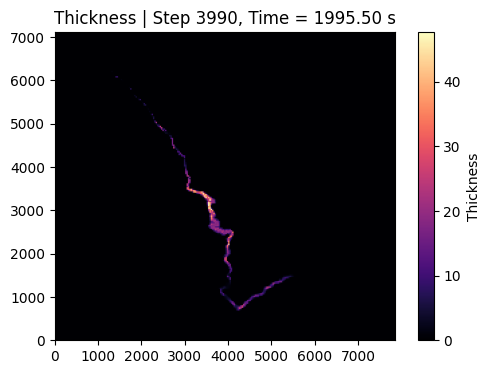

  [START] Initial Vol: 588044.60 m³
t=1995.50 | Dist: 6900.3m | Erosion: 7991256.6m³


In [ ]:
import os
import glob

# ---- Clear old saved CSVs before this run ----
sim_results_dir = "sim_results"
os.makedirs(sim_results_dir, exist_ok=True)

old_files = glob.glob(os.path.join(sim_results_dir, "*.csv"))
for f in old_files:
    os.remove(f)
print(f"Cleared {len(old_files)} old snapshot file(s) from '{sim_results_dir}'")



results = run_simulation(
                cohesion=run_params["cohesion"],
                delta_bed=run_params["delta_bed"],
                tau_crit_eros=run_params["tau_crit_eros"],
                k_eros=run_params["k_eros"],
                k_depos=run_params["k_depos"],
                bank_factor=run_params["bank_factor"],
                saturation_factor=run_params["saturation_factor"],
                tau_crit_depos=run_params["tau_crit_depos"],
                coef_u2_val=run_params["coef_u2"],
                viscosity=run_params["viscosity"],
                d_avg=run_params["d_avg"],
                rho=run_params["rho"],
                rho_solid=run_params["rho_solid"]
                )

In [ ]:
(h_final, eros_vol, init_vol, depos_vol, dist_m, history, umx, umy, z_live, e_bed_final,
 lateral_vol, max_vel, max_thick, depth_envelope, max_eros_depth) = results

runout_dist = dist_m
h_initial = np.loadtxt(thickness_file, delimiter=",")
z_initial = np.loadtxt(dem_file, delimiter=",")

initial_indices = np.where(h_initial > 0.1)
w = h_initial[initial_indices]
source_y = np.average(initial_indices[0], weights=w) * dy
source_x = np.average(initial_indices[1], weights=w) * dx
source_z = np.average(z_initial[initial_indices], weights=w)

In [ ]:
(h_final, eros_vol, init_vol, depos_vol, dist_m, history, umx, umy, z_live, e_bed_final,
 lateral_vol, max_vel, max_thick, depth_envelope, max_eros_depth) = results


print(f"source_x={source_x:.1f}, source_y={source_y:.1f}, source_z={source_z:.1f}")


# ============ RESULTS SUMMARY (for paper) ============
final_flow_vol   = np.sum(h_final[h_final > 0.1]) * dx * dy
vertical_eros_vol = eros_vol - lateral_vol
net_bed_change    = z_live - z_initial          # + = deposited, - = eroded
max_net_deposit_height = np.max(net_bed_change)
max_net_erosion_depth  = -np.min(net_bed_change)

print("\n" + "="*55)
print("SIMULATION SUMMARY")
print("="*55)
print(f"Initial (source) flow volume       : {init_vol:,.1f} m³")
print(f"Final (remaining) flow volume       : {final_flow_vol:,.1f} m³")
print(f"Total erosion volume (vert + lat)   : {eros_vol:,.1f} m³")
print(f"   - vertical erosion component     : {vertical_eros_vol:,.1f} m³")
print(f"   - lateral (bank) erosion component: {lateral_vol:,.1f} m³")
print(f"Total deposition volume             : {depos_vol:,.1f} m³")
print(f"Runout distance                     : {runout_dist:,.1f} m")
print(f"Max flow velocity (over full run)   : {max_vel:,.2f} m/s")
print(f"Max flow thickness (over full run)  : {max_thick:,.2f} m")
print(f"Max net deposit height (single cell): {max_net_deposit_height:,.2f} m")
print(f"Max net erosion depth (single cell) : {max_net_erosion_depth:,.2f} m")
print("-"*55)
mass_balance_diff = (init_vol + eros_vol) - (depos_vol + final_flow_vol)
print(f"Mass balance check (in - out)       : {mass_balance_diff:,.1f} m³ "
      f"({100*mass_balance_diff/max(init_vol+eros_vol,1e-6):.2f}% of total input)")
print("="*55 + "\n")

source_x=926.2, source_y=6476.3, source_z=1489.1

SIMULATION SUMMARY
Initial (source) flow volume       : 588,044.6 m³
Final (remaining) flow volume       : 8,593,167.0 m³
Total erosion volume (vert + lat)   : 8,000,000.0 m³
   - vertical erosion component     : 4,067,652.5 m³
   - lateral (bank) erosion component: 3,932,347.5 m³
Total deposition volume             : 130,857.9 m³
Runout distance                     : 6,922.4 m
Max flow velocity (over full run)   : 23.32 m/s
Max flow thickness (over full run)  : 47.21 m
Max net deposit height (single cell): 7.96 m
Max net erosion depth (single cell) : 30.00 m
-------------------------------------------------------
Mass balance check (in - out)       : -135,980.2 m³ (-1.58% of total input)



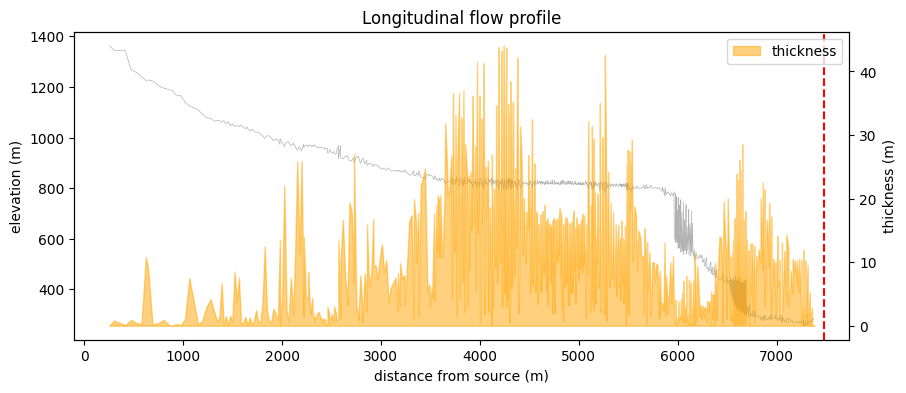

In [ ]:
import matplotlib.pyplot as plt

wet_idx = np.where(h_final > 0.05)
dist_along = np.sqrt((wet_idx[1]*dx - source_x)**2 + (wet_idx[0]*dy - source_y)**2)
elev_along = z_live[wet_idx]
thick_along = h_final[wet_idx]

order = np.argsort(dist_along)
fig, ax1 = plt.subplots(figsize=(10,4))
ax1.plot(dist_along[order], elev_along[order], 'k-', lw=0.5, alpha=0.3, label='terrain (scattered wet cells)')
ax1.set_ylabel('elevation (m)')
ax2 = ax1.twinx()
ax2.fill_between(dist_along[order], thick_along[order], color='orange', alpha=0.5, label='thickness')
ax2.set_ylabel('thickness (m)')
ax1.set_xlabel('distance from source (m)')
ax1.axvline(runout_dist, color='red', linestyle='--', label='current front')
plt.title('Longitudinal flow profile')
plt.legend(loc='upper right')
plt.show()

Printing OUTPUT FIGURES

Maximum flow-depth envelope

Found 400 saved thickness snapshots.


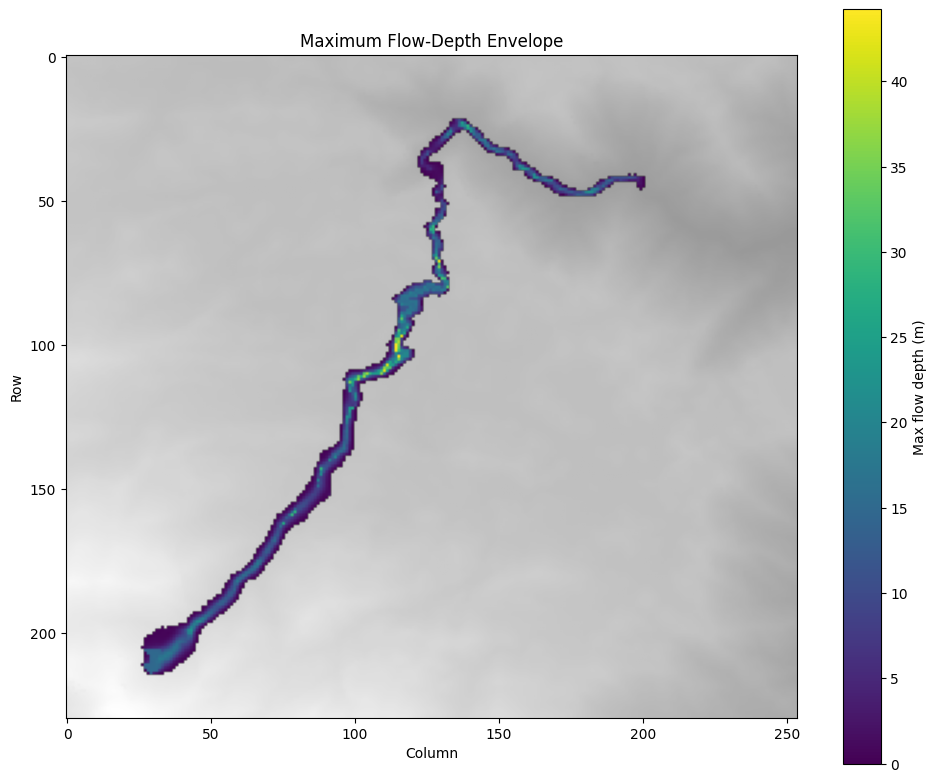

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pandas as pd
from glob import glob
import os

# Since output_mode="step" in your run, filenames are thickness_0000.csv, thickness_0020.csv, ...
thickness_files = sorted(glob(os.path.join("sim_results", "thickness_*.csv")))
print(f"Found {len(thickness_files)} saved thickness snapshots.")

max_depth_envelope = np.zeros_like(z_initial)
for f in thickness_files:
    h_snap = np.loadtxt(f, delimiter=",")
    max_depth_envelope = np.maximum(max_depth_envelope, h_snap)

# safety net: include the true final state, in case it wasn't itself a saved multiple of 20
max_depth_envelope = np.maximum(max_depth_envelope, h_final)

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(z_initial, cmap="gray", alpha=0.4)   # DEM as context background
masked_envelope = np.ma.masked_where(max_depth_envelope < 0.1, max_depth_envelope)
im = ax.imshow(masked_envelope, cmap="viridis", vmin=0)
plt.colorbar(im, ax=ax, label="Max flow depth (m)")
ax.set_title("Maximum Flow-Depth Envelope")
ax.set_xlabel("Column"); ax.set_ylabel("Row")
plt.tight_layout()
plt.savefig("max_depth_envelope.png", dpi=300)
plt.show()

Net bed-change map

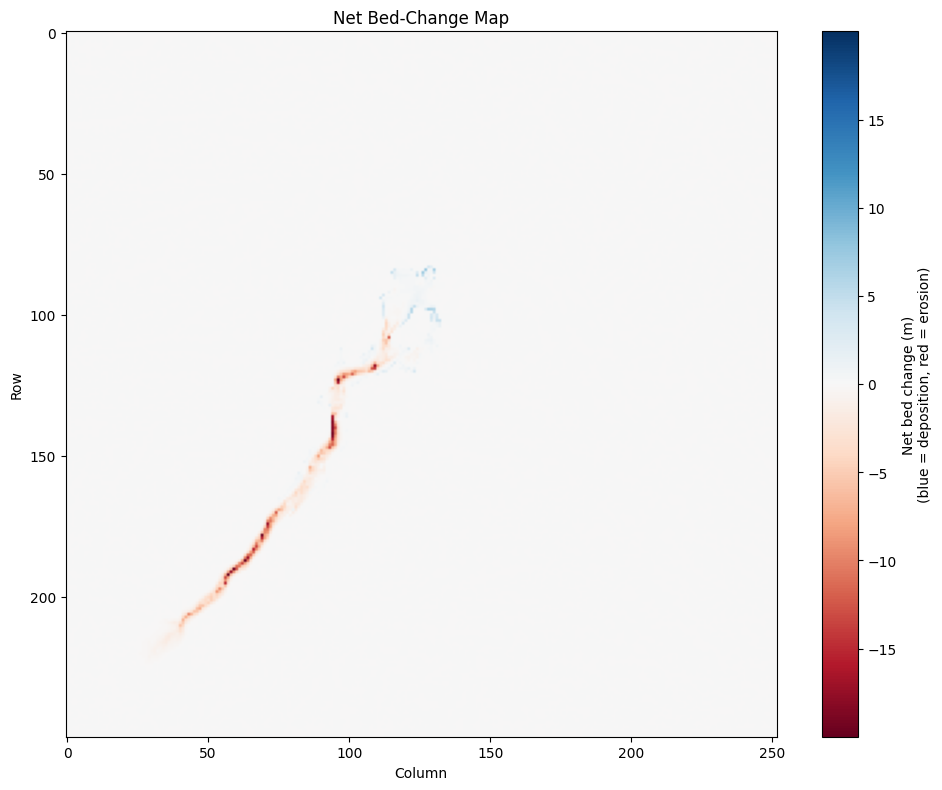

Max net deposition (single cell) : 7.38 m
Max net erosion depth (single cell): 20.00 m


In [ ]:
net_bed_change = z_live - z_initial   # + = net deposition, − = net erosion

vmax_change = np.nanmax(np.abs(net_bed_change))
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(net_bed_change, cmap="RdBu", vmin=-vmax_change, vmax=vmax_change)
plt.colorbar(im, ax=ax, label="Net bed change (m)\n(blue = deposition, red = erosion)")
ax.set_title("Net Bed-Change Map")
ax.set_xlabel("Column"); ax.set_ylabel("Row")
plt.tight_layout()
plt.savefig("net_bed_change_map.png", dpi=300)
plt.show()

print(f"Max net deposition (single cell) : {np.nanmax(net_bed_change):.2f} m")
print(f"Max net erosion depth (single cell): {-np.nanmin(net_bed_change):.2f} m")

Time-series / evolution figure

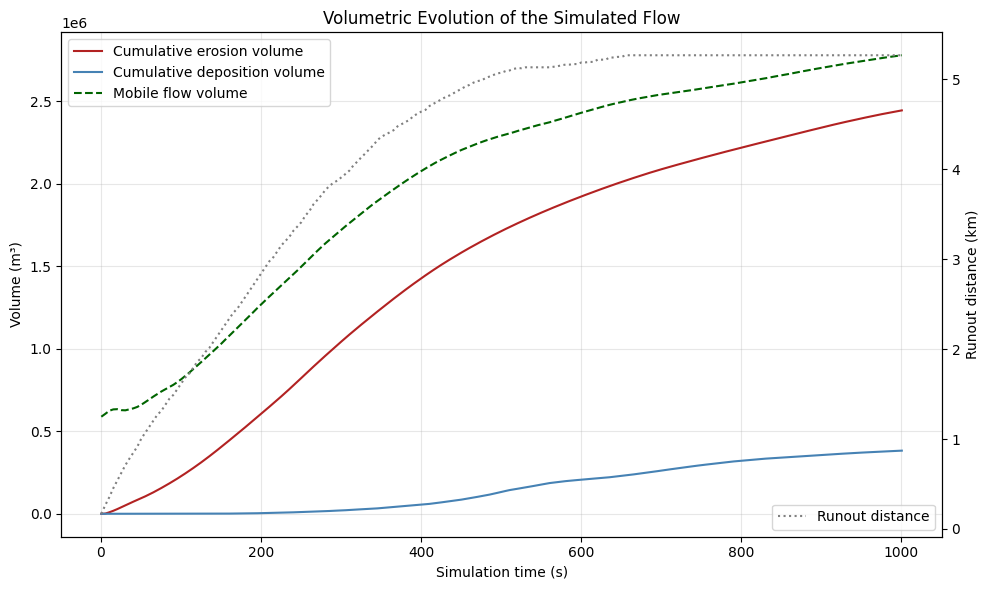

In [ ]:
hist_df = pd.DataFrame(history, columns=["step", "t_sec", "max_h", "eros_vol_m3", "depos_vol_m3", "runout_km"])

# mobile flow volume at each saved snapshot, matched to real sim time via hist_df
flow_vol_records = []
for f in thickness_files:
    step_num = int(os.path.basename(f).split("_")[1].split(".")[0])
    h_snap = np.loadtxt(f, delimiter=",")
    vol = np.sum(h_snap[h_snap > 0.1]) * dx * dy
    nearest = hist_df.iloc[(hist_df["step"] - step_num).abs().argsort()[:1]]
    t_match = nearest["t_sec"].values[0] if len(nearest) else np.nan
    flow_vol_records.append((step_num, t_match, vol))

flow_vol_df = pd.DataFrame(flow_vol_records, columns=["step", "t_sec", "flow_vol_m3"]).sort_values("t_sec")

fig, ax1 = plt.subplots(figsize=(10, 6))
ax1.plot(hist_df["t_sec"], hist_df["eros_vol_m3"], label="Cumulative erosion volume", color="firebrick")
ax1.plot(hist_df["t_sec"], hist_df["depos_vol_m3"], label="Cumulative deposition volume", color="steelblue")
ax1.plot(flow_vol_df["t_sec"], flow_vol_df["flow_vol_m3"], label="Mobile flow volume", color="darkgreen", linestyle="--")
ax1.set_xlabel("Simulation time (s)"); ax1.set_ylabel("Volume (m³)")
ax1.set_title("Volumetric Evolution of the Simulated Flow")
ax1.legend(loc="upper left"); ax1.grid(alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(hist_df["t_sec"], hist_df["runout_km"], label="Runout distance", color="gray", linestyle=":")
ax2.set_ylabel("Runout distance (km)")
ax2.legend(loc="lower right")

plt.tight_layout()
plt.savefig("volume_time_evolution.png", dpi=300)
plt.show()

CSI / Jaccard index vs. field-mapped extent

Simulated wetted cells : 1,745
Field-mapped cells     : 1,167
CSI / Jaccard Index    : 0.552
Precision              : 0.594
Recall                 : 0.888


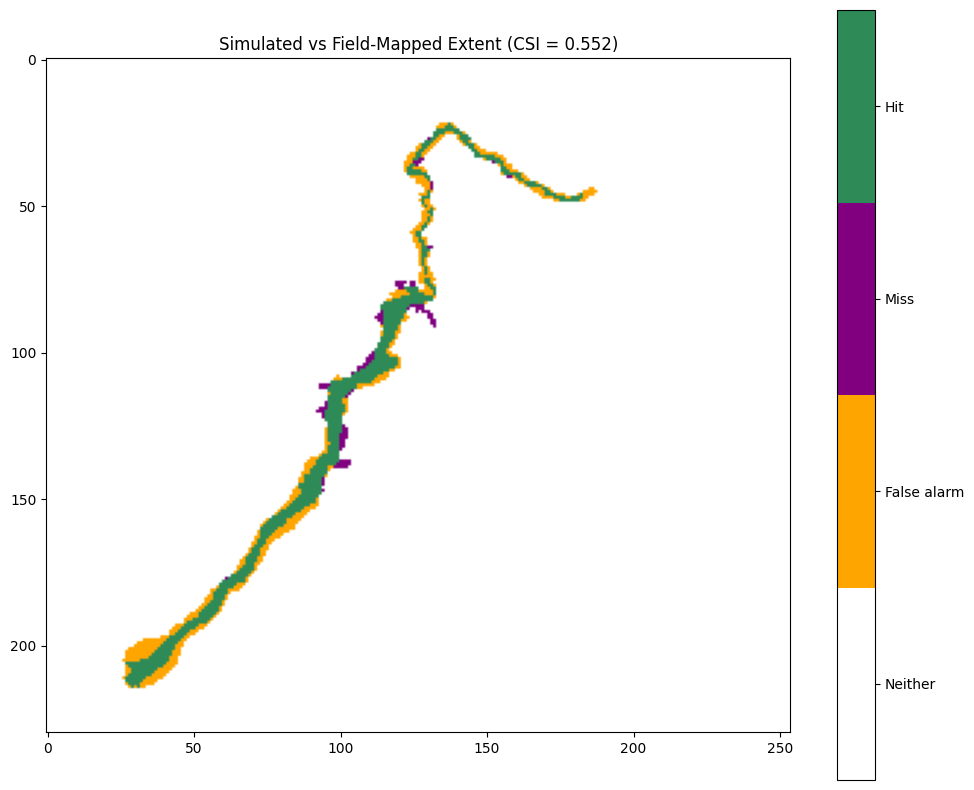

In [ ]:
import geopandas as gpd
from rasterio.features import geometry_mask

# ---- Build the SIMULATED wetted-extent mask (needs max_depth_envelope from step 1) ----
depth_threshold = 0.1   # m — match whatever minimum-depth criterion your field mapping used
simulated_extent = (max_depth_envelope > depth_threshold)

# ---- Build the FIELD-MAPPED extent mask ----


# Option B: if your CSV boundary is ALREADY a 0/1 raster mask on the same grid,
# skip Option A entirely and just do:
field_extent = np.loadtxt("/content/model_inputs/wayanad_2024_true_mask.csv", delimiter=",").astype(bool)

# ---- CSI / Jaccard ----
intersection = np.logical_and(simulated_extent, field_extent).sum()
union        = np.logical_or(simulated_extent, field_extent).sum()
false_alarm  = np.logical_and(simulated_extent, ~field_extent).sum()
miss         = np.logical_and(~simulated_extent, field_extent).sum()

csi       = intersection / union if union > 0 else np.nan
precision = intersection / (intersection + false_alarm) if (intersection + false_alarm) > 0 else np.nan
recall    = intersection / (intersection + miss) if (intersection + miss) > 0 else np.nan

print(f"Simulated wetted cells : {simulated_extent.sum():,}")
print(f"Field-mapped cells     : {field_extent.sum():,}")
print(f"CSI / Jaccard Index    : {csi:.3f}")
print(f"Precision              : {precision:.3f}")
print(f"Recall                 : {recall:.3f}")

# ---- Visual overlay: hit / miss / false-alarm map ----
overlay = np.zeros(z_initial.shape, dtype=int)
overlay[np.logical_and(simulated_extent, ~field_extent)] = 1   # model over-predicts
overlay[np.logical_and(~simulated_extent, field_extent)] = 2   # model under-predicts
overlay[np.logical_and(simulated_extent, field_extent)]  = 3   # agreement

cmap = mcolors.ListedColormap(["white", "orange", "purple", "seagreen"])
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(overlay, cmap=cmap, vmin=0, vmax=3)
cbar = plt.colorbar(im, ax=ax, ticks=[0.375, 1.125, 1.875, 2.625])
cbar.ax.set_yticklabels(["Neither", "False alarm", "Miss", "Hit"])
ax.set_title(f"Simulated vs Field-Mapped Extent (CSI = {csi:.3f})")
plt.tight_layout()
plt.savefig("extent_agreement_map.png", dpi=300)
plt.show()

In [ ]:

r = results   # or just use results_best directly below instead of r

from scipy.ndimage import gaussian_filter

z_orig = np.asarray(np.loadtxt(dem_file, delimiter=","))
z_orig = gaussian_filter(z_orig, sigma=0.2)
dirxz, diryz, slopexz, slopeyz = compute_interface_slope_features(z_orig, dx, dy)

slope_deg = np.degrees(np.arctan(np.sqrt(
    np.pad(np.tan(slopexz)**2, ((0,0),(0,1)), mode='edge') +
    np.pad(np.tan(slopeyz)**2, ((0,1),(0,0)), mode='edge')
)))
h_final    = r[13]        # max_depth_envelope
vel        = np.sqrt(r[6]**2 + r[7]**2)
slope_deg  = slope_deg   # reconstructed above, from z_orig

In [ ]:
# Find the actual leading tip — farthest wet cell from source, same
# definition as runout_dist itself — not just the thickest pile.
wet_idx = np.where(h_final > 0.05)
dist_all = np.sqrt((wet_idx[1]*dx - source_x)**2 + (wet_idx[0]*dy - source_y)**2 + (z_live[wet_idx] - source_z)**2)
tip_local_idx = np.argmax(dist_all)
tip_row, tip_col = wet_idx[0][tip_local_idx], wet_idx[1][tip_local_idx]

h_tip = h_final[tip_row, tip_col]
v_tip = np.sqrt(umx[tip_row, tip_col]**2 + umy[tip_row, tip_col]**2)
slope_tip = slope_deg[tip_row, tip_col]

print(f"Leading tip: row={tip_row}, col={tip_col}, h={h_tip:.3f}m, v={v_tip:.4f}m/s, local slope={slope_tip:.1f}°")

# All FOUR resistance terms this time, including cohesion — which is
# STILL a uniform global scalar, never made slope-dependent
delta_bed_here = np.radians(FIXED_PARAMS["delta_bed"] * 0.3 if slope_tip < 9 else FIXED_PARAMS["delta_bed"])
coef_C_here = FIXED_PARAMS["cohesion"] / FIXED_PARAMS["rho"]

coulomb_term = np.tan(delta_bed_here) * 9.81
cohesion_term = coef_C_here / h_tip
turbulent_term = FIXED_PARAMS["coef_u2"] * v_tip / h_tip
viscous_term = (3 * FIXED_PARAMS["viscosity"] / FIXED_PARAMS["rho"]) / h_tip**2

print(f"\nCoulomb (slope-adjusted): {coulomb_term:.5f}")
print(f"Cohesion (coef_C/h, still UNIFORM):   {cohesion_term:.5f}")
print(f"Turbulent (coef_u2·v/h):  {turbulent_term:.5f}")
print(f"Viscous:                  {viscous_term:.5f}")

Leading tip: row=84, col=129, h=6.308m, v=0.0593m/s, local slope=3.5°

Coulomb (slope-adjusted): 0.05137
Cohesion (coef_C/h, still UNIFORM):   0.00088
Turbulent (coef_u2·v/h):  0.00094
Viscous:                  0.00042


Parmeter Testing- -AUTOMATIC

*   List item
*   List item





In [ ]:
# Run this ONCE, before the sweep starts — none of this needs a simulation
# to have run; it only depends on your input files (thickness, DEM, true_mask)
true_mask = np.loadtxt('/content/model_inputs/wayanad_2024_true_mask.csv', delimiter=",")
z_initial = np.loadtxt(dem_file, delimiter=",")
h_initial = np.loadtxt(thickness_file, delimiter=",")

# Source point = mass-weighted centroid of the initial release
initial_indices = np.where(h_initial > 0.1)
w = h_initial[initial_indices]
source_y = np.average(initial_indices[0], weights=w) * dy
source_x = np.average(initial_indices[1], weights=w) * dx
source_z = np.average(z_initial[initial_indices], weights=w)

# True boundary's max distance from that same source point
true_wet = np.where(true_mask > 0)
true_xs = true_wet[1] * dx
true_ys = true_wet[0] * dy
true_zs = z_initial[true_wet]
true_dist = np.sqrt((true_xs - source_x)**2 + (true_ys - source_y)**2 + (true_zs - source_z)**2)
true_length_m = float(np.max(true_dist))

print(f"source_x={source_x:.1f}, source_y={source_y:.1f}, source_z={source_z:.1f}")
print(f"True boundary's max distance from source: {true_length_m:.1f} m")

source_x=864.3, source_y=6785.5, source_z=1498.4
True boundary's max distance from source: 7006.5 m


In [ ]:
BASELINE = {
      "delta_bed": 3,

      "coef_u2": 0.0297753,   #perfect0.005

      "rho": 1800,

      "saturation_factor": 0.95,

      "bank_factor": 0.0610468, #ok0.01

      "d_avg": 0.00498571,

      "tau_crit_eros": 537.668, #750-100perfect

      "k_eros": 7.20606e-06, #good

      "k_depos": 26.8667, #ok1000-500

      "tau_crit_depos": 502.85,   #600-750ok

      "cohesion": 100,  #150-100

      "rho_solid": 2650,

      "viscosity": 30,  #50_52.9246

}


In [ ]:

PARAM_RANGES = {
    "delta_bed": [0, 0.5, 1, 2, 3, 4, 5, 6, 8],   # degrees

    "coef_u2":        [0.0005, 0.0001, 0.005, 0.001, 0.01, 0.05, 0.1, 0.5, 1],


    "viscosity":      [1, 10, 20, 30, 40, 50, 60, 70, 80, 90],         # Pa·s — see #3, rebuilt entirely

    "k_eros":         [0.000001, 0.000002, 0.000005, 0.00001, 0.0001, 0.001, 0.01],
    "tau_crit_eros":  [50, 100, 200, 300, 400, 500, 600, 700, 800],


    "k_depos":        [0.4, 2, 10, 20, 50, 80, 100, 200, 300, 400, 500, 600, 700, 800],
    "tau_crit_depos": [50, 100, 200, 300, 400, 500, 600, 700, 800],          # Pa

    "d_avg": [
        0.000002,   # 2 µm   — clay
        0.00001,    # 10 µm  — fine silt
        0.00003,    # 30 µm  — medium silt
        0.00006,    # 60 µm  — coarse silt / silt-sand boundary
        0.00015,    # 150 µm — fine sand
        0.0004,     # 400 µm — medium sand (your old baseline)
        0.001,      # 1 mm   — coarse/very coarse sand
        0.003,      # 3 mm   — granule / fine gravel (your old ceiling)
        0.006,      # 6 mm   — fine gravel
    ],

    # fully remoulded/liquefied material at 0.95 saturation — 1500 Pa cohesion
    # in the old range isn't physically defensible at that saturation level
    "cohesion":       [0, 10, 20, 50, 100, 150, 250, 350, 450, 550, 600, 700, 800],

    "bank_factor":    [0.000001, 0.00001, 0.0001, 0.001, 0.01, 0.1, 1],            # lowered ceiling — see #5, and
                                                             # confirm this is even the right lever
}

In [ ]:
import gspread
from google.colab import auth
from google.auth import default

auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

SHEET_NAME = "wayanad_2024_calibration6"

try:
    sh = gc.open(SHEET_NAME)
    print(f"✅ Connected to existing Google Sheet: {SHEET_NAME}")
except gspread.exceptions.SpreadsheetNotFound:
    sh = gc.create(SHEET_NAME)
    print(f"✨ Created new Google Sheet: {SHEET_NAME}")

worksheet = sh.sheet1


✅ Connected to existing Google Sheet: wayanad_2024_calibration6


In [ ]:
import time as _time
# Add this near your other globals, before defining run_one
#last_run_state = {}

HEADER = ["run_id", "sweep_type", "swept_param", "swept_value"] + list(BASELINE.keys()) + \
         ["steps_used", "time_sec", "runout_dist_m", "true_length_m", "length_ratio",
          "total_eros_vol", "max_erosion_depth_m", "total_depos_vol", "total_lateral_vol",
          "max_velocity_ms", "max_thickness_m",
          "sim_wetted_cells", "field_wetted_cells", "csi", "precision", "recall",
          "hit_stall", "error"]

if worksheet.row_values(1) != HEADER:
    worksheet.clear()
    worksheet.append_row(HEADER)
    print("Added headers to the worksheet.")

def run_one(params, run_id, sweep_type, swept_param, swept_value):
    global last_run_state
    row_base = [run_id, sweep_type, swept_param, swept_value] + [params[k] for k in BASELINE.keys()]
    t0 = _time.time()
    try:
        results = run_simulation(
            cohesion=params["cohesion"], delta_bed=params["delta_bed"],
            tau_crit_eros=params["tau_crit_eros"], k_eros=params["k_eros"],
            k_depos=params["k_depos"], bank_factor=params["bank_factor"],
            saturation_factor=params["saturation_factor"], tau_crit_depos=params["tau_crit_depos"],
            coef_u2_val=params["coef_u2"], viscosity=params["viscosity"],
            d_avg=params["d_avg"], rho=params["rho"], rho_solid=params["rho_solid"],
        )
        (h_final, eros_vol, init_vol, depos_vol, dist_m, history, umx, umy, z_final, e_bed_final,
         lateral_vol, max_vel, max_thick, depth_envelope, max_eros_depth) = results

        # --- Extent agreement metrics, computed fresh for THIS run ---
        sim_extent = depth_envelope > 0.1   # match your field-mapping's minimum-depth criterion
        field_extent = true_mask.astype(bool)
        intersection = np.logical_and(sim_extent, field_extent).sum()
        union = np.logical_or(sim_extent, field_extent).sum()
        false_alarm = np.logical_and(sim_extent, ~field_extent).sum()
        miss = np.logical_and(~sim_extent, field_extent).sum()
        csi = intersection / union if union > 0 else float('nan')
        precision = intersection / (intersection + false_alarm) if (intersection + false_alarm) > 0 else float('nan')
        recall = intersection / (intersection + miss) if (intersection + miss) > 0 else float('nan')
        length_ratio = dist_m / true_length_m if true_length_m > 0 else float('nan')

        last_run_state = {
            "h": h_final, "umx": umx, "umy": umy, "z": z_final, "e_bed": e_bed_final,
            "history": history, "run_id": run_id, "depth_envelope": depth_envelope,
            "csi": csi, "precision": precision, "recall": recall,
        }

        steps_used = history[-1][0] if history else 0
        hit_stall = "stall" in str(history[-3:]) if history else False
        wall_s = _time.time() - t0
        row = row_base + [
            steps_used, round(wall_s, 1), round(dist_m, 1), round(true_length_m, 1), round(length_ratio, 3),
            round(eros_vol, 1), round(max_eros_depth, 2), round(depos_vol, 1), round(lateral_vol, 1),
            round(max_vel, 3), round(max_thick, 2),
            int(sim_extent.sum()), int(field_extent.sum()),
            round(csi, 4) if csi == csi else None,          # NaN-safe (NaN != NaN)
            round(precision, 4) if precision == precision else None,
            round(recall, 4) if recall == recall else None,
            hit_stall, "",
        ]
        print(f"✅ run {run_id} ({swept_param}={swept_value}): dist={dist_m:.0f}m "
              f"(true={true_length_m:.0f}m, ratio={length_ratio:.2f}) "
              f"eros={eros_vol:,.0f}m³ (max depth {max_eros_depth:.1f}m) "
              f"CSI={csi:.3f} ({wall_s:.0f}s)")
    except Exception as e:
        wall_s = _time.time() - t0
        row = row_base + [None]*17 + [None, str(e)[:200]]
        print(f"❌ run {run_id} ({swept_param}={swept_value}) failed: {e}")

    worksheet.append_row(row)
    return row

In [ ]:
run_id = 0

In [ ]:
for param_name, values in PARAM_RANGES.items():
    for val in values:
        params = BASELINE.copy()
        params[param_name] = val
        run_one(params, run_id, "OAT", param_name, val)
        run_id += 1

print(f"OAT sweep complete: {run_id} runs logged to '{SHEET_NAME}'.")

In [ ]:
from scipy.stats.qmc import LatinHypercube, scale
import numpy as np

param_names = list(PARAM_RANGES.keys())
lo = np.array([min(PARAM_RANGES[p]) for p in param_names])
hi = np.array([max(PARAM_RANGES[p]) for p in param_names])

# Pull the real next run_id from the sheet itself, same pattern as the
# surrogate-candidate cell — don't trust a local counter that could be
# stale or collide with rows already logged in a previous session.
all_rows = worksheet.get_all_records()
run_id = max([r.get("run_id", 0) for r in all_rows], default=0) + 1


In [ ]:

N_LHS = 100
sampler = LatinHypercube(d=len(param_names), seed=42)
unit_samples = sampler.random(N_LHS)
lhs_samples = scale(unit_samples, lo, hi)

for i, sample in enumerate(lhs_samples):
    params = BASELINE.copy()
    for name, val in zip(param_names, sample):
        params[name] = float(val)
    run_one(params, run_id, "LHS", "ALL", "joint")
    run_id += 1

print(f"LHS batch complete: {len(lhs_samples)} runs logged.")

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

all_rows = worksheet.get_all_records()
df = pd.DataFrame(all_rows)
# Use the NEW columns — drop rows missing any of them, not the old names
df = df.dropna(subset=["total_eros_vol", "max_erosion_depth_m", "csi", "length_ratio"])

X = df[param_names].astype(float)
targets = {
    "total_eros_vol":      df["total_eros_vol"].astype(float),
    "max_erosion_depth_m": df["max_erosion_depth_m"].astype(float),
    "length_ratio":        df["length_ratio"].astype(float),
    "csi":                 df["csi"].astype(float),
}

surrogates = {}
for target_name, y in targets.items():
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
    model = RandomForestRegressor(n_estimators=300, random_state=42)
    model.fit(Xtr, ytr)
    r2 = r2_score(yte, model.predict(Xte))
    print(f"{target_name}: test R² = {r2:.3f}  (below ~0.5 means: not enough data yet, run more)")
    surrogates[target_name] = model

    importances = pd.Series(model.feature_importances_, index=param_names).sort_values(ascending=False)
    print(importances.head(5), "\n")

In [ ]:
from scipy.optimize import differential_evolution

# Goal-aligned targets:
#   - erosion volume near 5.5-6M m³ (your stated target range, midpoint used)
#   - max erosion depth near 30 m
#   - length_ratio near 1.0 (simulated max distance == true boundary's max distance)
#   - csi near 1.0 (perfect spatial extent agreement) — cost uses (1 - csi)
TARGETS = {"total_eros_vol": 5.75e6, "max_erosion_depth_m": 30.0, "length_ratio": 1.0, "csi": 1.0}
WEIGHTS = {"total_eros_vol": 1/5.75e6, "max_erosion_depth_m": 1/30.0, "length_ratio": 1.0, "csi": 1.0}

In [ ]:
param_names = list(PARAM_RANGES.keys())
lo = np.array([min(PARAM_RANGES[p]) for p in param_names])
hi = np.array([max(PARAM_RANGES[p]) for p in param_names])
bounds = list(zip(lo, hi))

def surrogate_cost_vectorized(x):
    x_arr = np.asarray(x).T
    cost = np.zeros(x_arr.shape[0])
    for name, model in surrogates.items():
        preds = model.predict(x_arr)
        if name == "csi":
            # csi is a similarity score to MAXIMIZE (1.0 = perfect), not
            # match toward a raw value the same way as the others
            cost += (WEIGHTS[name] * (1.0 - preds))**2
        else:
            cost += (WEIGHTS[name] * (preds - TARGETS[name]))**2
    return cost

opt_result = differential_evolution(
    surrogate_cost_vectorized, bounds, seed=42, maxiter=200, tol=1e-8,
    vectorized=True,
    disp=True,
)

best_params = dict(zip(param_names, opt_result.x))
print("\nSurrogate-suggested parameters (UNVERIFIED — run these on the real model next):")
for k, v in best_params.items():
    print(f"  {k}: {v:.6g}")


In [ ]:
from IPython.display import clear_output

In [ ]:
all_rows = worksheet.get_all_records()
run_id = max([r.get("run_id", 0) for r in all_rows], default=0) + 1

candidate = BASELINE.copy()
candidate.update(best_params)
run_one(candidate, run_id, "SURROGATE_CANDIDATE", "ALL", "optimized")

Accuracy assesment

In [ ]:
import numpy as np
import rasterio
from rasterio.features import rasterize
import geopandas as gpd
import matplotlib.colors as mcolors

# =========================================================
# ---- Inputs: upload these two files ----
# =========================================================
sim_tif_path   = "/content/full_flow_combined_10m.tif"   # full simulated depth/extent raster
true_shp_path  = "/content/chooralmala_outline1.shp"      # field-mapped true inundation boundary (polygon)

# ---- Read the simulated raster (gives us the grid: shape, transform, crs) ----
with rasterio.open(sim_tif_path) as src:
    max_depth_envelope = src.read(1).astype(float)
    ref_transform = src.transform
    ref_crs       = src.crs
    ref_shape     = src.shape
    ref_profile   = src.profile

# If the tif already stores a 0/1 extent mask rather than depth, this threshold
# step is a no-op in practice (anything >0.1 stays True) — keep it only if the
# tif stores depth values; set depth_threshold = 0 if it's already boolean.
depth_threshold = 0.1   # m — match whatever minimum-depth criterion your field mapping used
simulated_extent = (max_depth_envelope > depth_threshold)

# =========================================================
# ---- Build the FIELD-MAPPED extent mask from the shapefile ----
# =========================================================
true_gdf = gpd.read_file(true_shp_path)

# Reproject the shapefile to match the raster's CRS if needed
if true_gdf.crs != ref_crs:
    true_gdf = true_gdf.to_crs(ref_crs)

field_extent = rasterize(
    [(geom, 1) for geom in true_gdf.geometry],
    out_shape=ref_shape,
    transform=ref_transform,
    fill=0,
    dtype="uint8",
).astype(bool)

# =========================================================
# ---- CSI / Jaccard ----
# =========================================================
intersection = np.logical_and(simulated_extent, field_extent).sum()
union        = np.logical_or(simulated_extent, field_extent).sum()
false_alarm  = np.logical_and(simulated_extent, ~field_extent).sum()
miss         = np.logical_and(~simulated_extent, field_extent).sum()

csi       = intersection / union if union > 0 else np.nan
precision = intersection / (intersection + false_alarm) if (intersection + false_alarm) > 0 else np.nan
recall    = intersection / (intersection + miss) if (intersection + miss) > 0 else np.nan

print(f"Simulated wetted cells : {simulated_extent.sum():,}")
print(f"Field-mapped cells     : {field_extent.sum():,}")
print(f"CSI / Jaccard Index    : {csi:.3f}")
print(f"Precision              : {precision:.3f}")
print(f"Recall                 : {recall:.3f}")

# =========================================================
# ---- Hit / miss / false-alarm overlay, written out as GeoTIFF ----
# =========================================================
overlay = np.zeros(ref_shape, dtype=np.uint8)
overlay[np.logical_and(simulated_extent, ~field_extent)] = 1   # model over-predicts (false alarm)
overlay[np.logical_and(~simulated_extent, field_extent)] = 2   # model under-predicts (miss)
overlay[np.logical_and(simulated_extent, field_extent)]  = 3   # agreement (hit)

import os

# ---- Make sure the output directory exists before writing ----
os.makedirs("/content/output_tif", exist_ok=True)

# ---- Build a clean output profile (drop tiling keys inherited from the source tif
#      that don't apply when writing an untiled GeoTIFF) ----
out_profile = ref_profile.copy()
out_profile.update(dtype="uint8", count=1, nodata=0, compress="lzw")
out_profile.pop("blockxsize", None)
out_profile.pop("blockysize", None)
out_profile["tiled"] = False

out_tif_path = "/content/output_tif/extent_agreement_map.tif"
with rasterio.open(out_tif_path, "w", **out_profile) as dst:
    dst.write(overlay, 1)

print(f"Overlay written to: {out_tif_path}")
print("Pixel codes — 0: neither, 1: false alarm, 2: miss, 3: hit")

Simulated wetted cells : 1,743
Field-mapped cells     : 1,173
CSI / Jaccard Index    : 0.555
Precision              : 0.597
Recall                 : 0.887
Overlay written to: /content/output_tif/extent_agreement_map.tif
Pixel codes — 0: neither, 1: false alarm, 2: miss, 3: hit


# **Convert** csv to tiff

Use the '!' prefix to run shell commands in Jupyter/Colab notebooks

In [ ]:
print("Installing rasterio and required dependencies...")

Installing rasterio and required dependencies...


In [ ]:
# Install numpy and pandas just in case, and rasterio
!pip install rasterio numpy pandas
# Installing or upgrading gdal sometimes fixes common linking issues in Colab environments
!pip install --upgrade gdal

  Using cached gdal-3.13.3.tar.gz (940 kB)
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.


In [ ]:
print("Setup complete. You may proceed to run the conversion script.")

SAVE TO ZIP

In [ ]:
import numpy as np
import rasterio
from rasterio.transform import from_origin
import os
from pathlib import Path
from google.colab import files  # NEW: Added for downloading

In [ ]:
def convert_csv_to_tif(csv_file_path, output_raster_path, rows, cols, res, xmin, ymax, crs='EPSG:32643'):
    try:
        data = np.genfromtxt(csv_file_path, delimiter=",", filling_values=np.nan)

        if data.shape[0] != rows or data.shape[1] != cols:
            print(f"Warning: {os.path.basename(csv_file_path)} shape {data.shape} mismatch. Padding to ({rows}, {cols}).")
            padded_data = np.full((rows, cols), np.nan, dtype=data.dtype)
            padded_data[:min(rows, data.shape[0]), :min(cols, data.shape[1])] = data[:min(rows, data.shape[0]), :min(cols, data.shape[1])]
            data = padded_data

        transform = from_origin(xmin, ymax, res, res)

        profile = {
            'driver': 'GTiff',
            'height': rows,
            'width': cols,
            'count': 1,
            'dtype': rasterio.float32,
            'crs': crs,
            'transform': transform,
            'nodata': np.nan
        }

        with rasterio.open(output_raster_path, 'w', **profile) as dst:
            dst.write(data.astype(rasterio.float32), 1)

        print(f"Done: {os.path.basename(output_raster_path)}")

    except Exception as e:
        print(f"Error converting {csv_file_path}: {e}")

In [ ]:
def batch_convert_folder(input_folder, output_folder, rows, cols, res, xmin, ymax, crs='EPSG:32643'):
    if not os.path.exists(output_folder):
        os.makedirs(output_folder)
        print(f"Created output directory: {output_folder}")

    files_list = [f for f in os.listdir(input_folder) if f.endswith('.csv')]

    if not files_list:
        print("No CSV files found in the input folder.")
        return

    print(f"Found {len(files_list)} files. Starting conversion...")

    for filename in files_list:
        input_path = os.path.join(input_folder, filename)
        output_name = filename.replace('.csv', '.tif')
        output_path = os.path.join(output_folder, output_name)
        convert_csv_to_tif(input_path, output_path, rows, cols, res, xmin, ymax, crs)

In [ ]:
# --- CONFIGURATION ---
input_dir = "/content/sim_results"
output_dir = "/content/output_tif/"

In [ ]:
import rasterio

def get_grid_params_from_raster(reference_raster_path):
    """Extract rows, cols, res, xmin, ymax, crs from a reference raster."""
    with rasterio.open(reference_raster_path) as src:
        rows = src.height
        cols = src.width
        # assumes square pixels; if not, use src.res[0] / src.res[1] separately
        res = src.res[0]
        xmin = src.bounds.left
        ymax = src.bounds.top
        crs = src.crs.to_string()
    return rows, cols, res, xmin, ymax, crs

reference_raster = "/content/model_inputs/wayanad_2024_dem_burned.tif"
rows, cols, res, xmin, ymax, crs = get_grid_params_from_raster(reference_raster)

print(f"rows={rows}, cols={cols}, res={res}, xmin={xmin}, ymax={ymax}, crs={crs}")

batch_convert_folder(
    input_folder=input_dir,
    output_folder=output_dir,
    rows=rows,
    cols=cols,
    res=res,
    xmin=xmin,
    ymax=ymax,
    crs=crs
)

rows=230, cols=254, res=30.922, xmin=622923.6900000001, ymax=1274264.698, crs=EPSG:32643
Found 400 files. Starting conversion...
Done: thickness_0970.tif
Done: thickness_1550.tif
Done: thickness_3300.tif
Done: thickness_3600.tif
Done: thickness_1020.tif
Done: thickness_3210.tif
Done: thickness_3000.tif
Done: thickness_3930.tif
Done: thickness_2000.tif
Done: thickness_0000.tif
Done: thickness_3650.tif
Done: thickness_1540.tif
Done: thickness_2610.tif
Done: thickness_3960.tif
Done: thickness_2600.tif
Done: thickness_0670.tif
Done: thickness_3400.tif
Done: thickness_3370.tif
Done: thickness_1250.tif
Done: thickness_2760.tif
Done: thickness_0510.tif
Done: thickness_3150.tif
Done: thickness_2080.tif
Done: thickness_0190.tif
Done: thickness_2240.tif
Done: thickness_0360.tif
Done: thickness_2140.tif
Done: thickness_2750.tif
Done: thickness_3050.tif
Done: thickness_1510.tif
Done: thickness_1630.tif
Done: thickness_2870.tif
Done: thickness_3800.tif
Done: thickness_1650.tif
Done: thickness_0390.

In [ ]:
import os
import glob
import numpy as np
import rasterio

def save_combined_and_last_flow(output_folder, combined_out_path, last_out_path):
    tif_files = sorted(glob.glob(os.path.join(output_folder, "*.tif")))
    if not tif_files:
        print("No tif files found in output folder.")
        return

    # --- Combined (max-over-time) flow ---
    with rasterio.open(tif_files[0]) as src0:
        profile = src0.profile
        max_array = src0.read(1).astype(np.float32)

    for f in tif_files[1:]:
        with rasterio.open(f) as src:
            arr = src.read(1).astype(np.float32)
            max_array = np.maximum(max_array, arr)

    profile.update(dtype=rasterio.float32)
    os.makedirs(os.path.dirname(combined_out_path), exist_ok=True)
    with rasterio.open(combined_out_path, 'w', **profile) as dst:
        dst.write(max_array, 1)
    print(f"Saved combined (max) flow tif: {combined_out_path}")

    # --- Last timestep flow ---
    last_file = tif_files[-1]
    with rasterio.open(last_file) as src:
        last_array = src.read(1)
        last_profile = src.profile

    os.makedirs(os.path.dirname(last_out_path), exist_ok=True)
    with rasterio.open(last_out_path, 'w', **last_profile) as dst:
        dst.write(last_array, 1)
    print(f"Saved last flow tif: {last_out_path} (source: {os.path.basename(last_file)})")


In [ ]:
save_combined_and_last_flow(
    output_folder=output_dir,  # /content/output_tif/
    combined_out_path="/content/model_outputs/full_flow_combined_15m.tif",
    last_out_path="/content/model_outputs/last_flow_15m.tif"
)

Saved combined (max) flow tif: /content/model_outputs/full_flow_combined_15m.tif
Saved last flow tif: /content/model_outputs/last_flow_15m.tif (source: thickness_3990.tif)


In [ ]:
# --- NEW: DOWNLOAD SECTION ---
print("\nPreparing for download...")
import shutil

In [ ]:
# 1. Zip the output folder
zip_name = "Chooralmala_Results2"
shutil.make_archive(zip_name, 'zip', output_dir)

In [ ]:
# 2. Trigger the browser download
files.download(f"{zip_name}.zip")
print(f"Download of {zip_name}.zip triggered!")

# SAVING 3D FLOW VIDEO

Import the original function for the actual plotting logi
plot 1 scene to adjust

In [ ]:
!sudo apt update
!sudo apt install ffmpeg

In [ ]:
!ls -F
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
import os
import glob
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import LightSource # <-- FIX FOR LightSource ERROR
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

In [ ]:
# --- ⚙️ CONFIGURATION & ZOOM ---
DATA_DIR = "output_h"
DEM_FILE_PATH = "/content/dem_chooralmala_new.csv"
dx, dy = 12.49, 12.49
H_MAX_GLOBAL = 40.0
H_FLOW_MIN = 0.1

In [ ]:
# Zoom in coordinates (Adjusted for better flow visibility based on the image)
X_MIN_PLOT, X_MAX_PLOT = 500, 6000
Y_MIN_PLOT, Y_MAX_PLOT = 0, 5000 # ⬆️ ADJUSTED: Increased Y_MAX_PLOT to capture more of the flow
# --- ------------------------ ---

In [ ]:
# --- Load DEM and define global variables ---
Z_DEM_STATIC = np.loadtxt(DEM_FILE_PATH, delimiter=",")
nrow, ncol = Z_DEM_STATIC.shape
x_coords = np.arange(0, ncol * dx, dx)
y_coords = np.arange(0, nrow * dy, dy)
X, Y = np.meshgrid(x_coords, y_coords)

In [ ]:
Z_MIN_GLOBAL = np.min(Z_DEM_STATIC)
Z_MAX_GLOBAL = np.max(Z_DEM_STATIC)

In [ ]:
if not os.path.exists("animation_frames_static_dem_refined"):
    os.makedirs("animation_frames_static_dem_refined")
# --- 2. TEMPORARY FUNCTION: Load or Create Flow Data (h) ---
def load_sample_h_data():
    """Loads the first 'flow_depth_t*.csv' file or generates a placeholder."""

    # ➒ FIX 1: Search for the correct filename pattern
    h_files = sorted(glob.glob(os.path.join(DATA_DIR, 'flow_depth_t*.csv')))

    if h_files:
        sample_file = h_files[300]
        h_data = np.loadtxt(sample_file, delimiter=",")

        # ➒ FIX 2: Correctly extract time step from the new filename format
        # Example: 'flow_depth_t001.5.csv' -> '001.5' -> 1.5
        filename_base = os.path.basename(sample_file)
        time_part = filename_base.split('_t')[1].replace('.csv', '')
        time_step = float(time_part)

        if h_data.shape != Z_DEM_STATIC.shape:
            raise ValueError(f"Flow data shape {h_data.shape} mismatch with DEM shape {Z_DEM_STATIC.shape}")

        print(f"Loaded flow data from: {os.path.basename(sample_file)}")
        print(f"File time step: t = {time_step:.1f} s")
        return h_data, time_step
    else:
        # Placeholder (Gaussian hill) logic remains for when no files are found
        h_placeholder = 15 * np.exp(-((X - X.mean())**2 + (Y - Y.mean())**2) / (2 * (50000**2)))
        print(f"❌ WARNING: No flow files found in '{DATA_DIR}'. Using placeholder data (Max h: {h_placeholder.max():.1f}m).")
        return h_placeholder, 0.0


  # --- 3. THE ORIGINAL PLOTTING FUNCTION (MODIFIED) ---
def plot_single_surface(h_data, time_step):
    """
    Generates a 3D plot of the flow surface (Z_DEM_STATIC + h)
    with a zoomed-in view, no grid lines, and a dark blue flow color.
    """

    # ➡️ CRITICAL FIX: Add a tiny Z-offset to lift the flow surface above the DEM.
    FLOW_OFFSET = 1e-4 # 0.1 millimeter offset to prevent Z-fighting.

    Z_surface_PLOT = Z_DEM_STATIC + h_data + FLOW_OFFSET # <--- APPLY OFFSET

    mask = h_data < H_FLOW_MIN

    C = np.clip(h_data, H_FLOW_MIN, H_MAX_GLOBAL) # C still based on h_data (not offset)


    fig = plt.figure(figsize=(8, 6)) # ⬆️ ADJUSTED: Increased figure size for better visibility
    ax = fig.add_subplot(111, projection='3d')

    # --- ➒ VIEWING ANGLE AND GRID ADJUSTMENTS ➒ ---
    ax.view_init(elev=30, azim=-65) # ⬆️ ADJUSTED: Changed azim from -80 to -65 for a slightly more direct view
    ax.autoscale_view(tight=True)
    ax.grid(False) # Removed major grid lines

    # --- ➒ ZOOM IN (Set X and Y limits) ➒ ---
    ax.set_xlim(X_MIN_PLOT, X_MAX_PLOT)
    ax.set_ylim(Y_MIN_PLOT, Y_MAX_PLOT)

    # --- ENHANCED LIGHTING SETUP ---
    ls = LightSource(azdeg=225, altdeg=45) # Light from top-left-back for dramatic effect

    # 3. Plot the Static DEM (Terrain)
    ax.plot_surface(X, Y, Z_DEM_STATIC,
                    facecolors=ls.shade(Z_DEM_STATIC, cmap=cm.terrain, vert_exag=0.5, blend_mode='soft'),
                    alpha=0.98,
                    linewidth=0.0,
                    edgecolor='none',
                    antialiased=False,
                    rcount=200, ccount=200,# ⬇️ ADJUSTED: Reduced count for FASTER plotting
                    shade=False)


    FLOW_COLORMAP = plt.colormaps.get_cmap('Blues_r')
    # Calculate the RGB colors based on C, respecting the Z_surface_masked nan values
    colors_rgb = FLOW_COLORMAP(C / H_MAX_GLOBAL)
    colors_rgb[mask, 3] = 0.0

    # 4. Plot the Flow Surface using the offsetted Z values
    surf = ax.plot_surface(X, Y, Z_surface_PLOT, # <--- 💡 PLOT THE *FULL* Z_surface_PLOT
                            facecolors=colors_rgb,
                            vmin=H_FLOW_MIN, vmax=H_MAX_GLOBAL,
                            linewidth=0.0,
                            edgecolor='none',
                            antialiased=False,
                            rcount=200, ccount=200, # ⬇️ ADJUSTED: Reduced count for FASTER plotting
                            shade=False)

    # --- Add a subtle base plane to fill the "empty space" below the terrain ---
    zmin_plot = Z_MIN_GLOBAL # or a specific low value
    verts = [list(zip([X_MIN_PLOT, X_MAX_PLOT, X_MAX_PLOT, X_MIN_PLOT],
                      [Y_MIN_PLOT, Y_MIN_PLOT, Y_MAX_PLOT, Y_MAX_PLOT],
                      [zmin_plot, zmin_plot, zmin_plot, zmin_plot]))]
    ax.add_collection3d(Poly3DCollection(verts, alpha=0.1, facecolor='grey', linewidth=0))

    # 5. Labels, Title, and Limits


    ax.set_title(f'Debris Flow Simulation (t = {time_step:.1f} s)', fontsize=20, pad=30)

    # Z-limits remain relative to global DEM min/max

    # Tweak Z-axis formatter to avoid scientific notation if possible



    # Remove the z-axis pane lines for a cleaner look
    ax.xaxis.pane.fill = False

    ax.xaxis.pane.set_edgecolor('w')
    ax.yaxis.pane.set_edgecolor('w')


    # CRITICAL FIX: Ensure the color of the pane itself is transparent/white
    ax.xaxis.pane.set_alpha(0)
    ax.yaxis.pane.set_alpha(0)


    mappable = cm.ScalarMappable(cmap=FLOW_COLORMAP)
    mappable.set_array(C)
    mappable.set_clim(H_FLOW_MIN, H_MAX_GLOBAL)
    cb = fig.colorbar(mappable, ax=ax, shrink=0.7, aspect=20, label='Flow Depth $h$ (m)', pad=0.05)

    cb.set_label('Flow Depth $h$ (m)', fontsize=12, labelpad=15)

    plt.tight_layout(rect=[0, 0, 0.9, 1])
    #plt.show()

In [ ]:
# --- 4. EXECUTION ---
if __name__ == '__main__':
    try:
        sample_h_data, sample_time_step = load_sample_h_data()

        # ➡️ DATA CHECK: Validate flow data within the zoomed area
        # Find indices corresponding to the plot limits
        x_indices = np.where((x_coords >= X_MIN_PLOT) & (x_coords <= X_MAX_PLOT))[0]
        y_indices = np.where((y_coords >= Y_MIN_PLOT) & (y_coords <= Y_MAX_PLOT))[0]

        if x_indices.size > 0 and y_indices.size > 0:
            # Slice the flow data to the zoomed area
            h_zoomed = sample_h_data[y_indices.min():y_indices.max()+1, x_indices.min():x_indices.max()+1]
            max_h_zoomed = np.max(h_zoomed)

            if max_h_zoomed < H_FLOW_MIN:
                print(f"⚠️ **WARNING:** Max flow depth in the zoomed area is {max_h_zoomed:.4f}m.")
                print(f"Flow is BELOW the H_FLOW_MIN={H_FLOW_MIN}m threshold, so it will be entirely masked out.")
            else:
                print(f"✅ Flow data FOUND in zoomed area. Max h = {max_h_zoomed:.2f}m.")

        plot_single_surface(sample_h_data, sample_time_step)
        print("Plot window opened. Adjust configuration variables and rerun to view changes.")
    except ValueError as e:
        print(f"Execution Error: {e}")

In [ ]:
DATA_DIR = "output_h"
DEM_FILE_PATH = "/content/dem_chooralmala_new.csv"
dx, dy = 12.49, 12.49
H_MAX_GLOBAL = 40.0
H_FLOW_MIN = 0.1
OUTPUT_FRAMES_DIR = "animation_frames_static_dem_refined"

In [ ]:
# Load DEM and define global variables once
Z_DEM_STATIC = np.loadtxt(DEM_FILE_PATH, delimiter=",")
nrow, ncol = Z_DEM_STATIC.shape
x_coords = np.arange(0, ncol * dx, dx)
y_coords = np.arange(0, nrow * dy, dy)
X, Y = np.meshgrid(x_coords, y_coords)

In [ ]:
Z_MIN_GLOBAL = np.min(Z_DEM_STATIC)
Z_MAX_GLOBAL = np.max(Z_DEM_STATIC)

In [ ]:
if not os.path.exists(OUTPUT_FRAMES_DIR):
    os.makedirs(OUTPUT_FRAMES_DIR)
# --- END GLOBAL SETUP ---

In [ ]:
def create_3d_frame_static_dem(h_data, time_step, output_path):
    """
    Generates a 3D plot of the flow surface (Z_DEM_STATIC + h)
    for a single time step and saves it to a file.

    NOTE: Relies on global variables (X, Y, Z_DEM_STATIC, H_MAX_GLOBAL, etc.)
    defined in the setup section above.
    """

    # ➡️ CRITICAL FIX: Add a tiny Z-offset to lift the flow surface above the DEM.
    FLOW_OFFSET = 1e-4

    Z_surface_PLOT = Z_DEM_STATIC + h_data + FLOW_OFFSET
    mask = h_data < H_FLOW_MIN
    C = np.clip(h_data, H_FLOW_MIN, H_MAX_GLOBAL)

    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection='3d')

    # --- VIEWING ANGLE AND AXIS SETUP ---
    ax.view_init(elev=30, azim=-65)
    ax.autoscale_view(tight=True)
    ax.grid(False)

    # --- ZOOM IN (Set X and Y limits) ---
    ax.set_xlim(X_MIN_PLOT, X_MAX_PLOT)
    ax.set_ylim(Y_MIN_PLOT, Y_MAX_PLOT)

    # --- ENHANCED LIGHTING SETUP ---
    ls = LightSource(azdeg=225, altdeg=45)

    # 3. Plot the Static DEM (Terrain)
    ax.plot_surface(X, Y, Z_DEM_STATIC,
                    facecolors=ls.shade(Z_DEM_STATIC, cmap=cm.terrain, vert_exag=0.5, blend_mode='soft'),
                    alpha=0.98, linewidth=0.0, edgecolor='none', antialiased=False,
                    rcount=200, ccount=200, shade=False)

    # 4. Plot the Flow Surface
    FLOW_COLORMAP = plt.colormaps.get_cmap('Blues_r')
    colors_rgb = FLOW_COLORMAP(C / H_MAX_GLOBAL)
    colors_rgb[mask, 3] = 0.0

    ax.plot_surface(X, Y, Z_surface_PLOT,
                    facecolors=colors_rgb,
                    vmin=H_FLOW_MIN, vmax=H_MAX_GLOBAL,
                    linewidth=0.0, edgecolor='none', antialiased=False,
                    rcount=200, ccount=200, shade=False)

    # --- Add a subtle base plane ---
    zmin_plot = Z_MIN_GLOBAL
    verts = [list(zip([X_MIN_PLOT, X_MAX_PLOT, X_MAX_PLOT, X_MIN_PLOT],
                      [Y_MIN_PLOT, Y_MIN_PLOT, Y_MAX_PLOT, Y_MAX_PLOT],
                      [zmin_plot, zmin_plot, zmin_plot, zmin_plot]))]
    ax.add_collection3d(Poly3DCollection(verts, alpha=0.1, facecolor='grey', linewidth=0))

    # 5. Labels and Title
    ax.set_xlabel('Easting (m)', fontsize=14, labelpad=15)
    ax.set_ylabel('Northing (m)', fontsize=14, labelpad=15)
    ax.set_title(f'Debris Flow Simulation (t = {time_step:.1f} s)', fontsize=20, pad=30)

    # Hide Z-axis elements (removed as requested)
    ax.set_yticks([]) # Hide Y-axis tick marks (to clean up residual lines)

    # Remove pane lines (kept for cleanliness)
    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False
    ax.xaxis.pane.set_edgecolor('w')
    ax.yaxis.pane.set_edgecolor('w')
    ax.zaxis.pane.set_edgecolor('w')
    ax.xaxis.pane.set_alpha(0)
    ax.yaxis.pane.set_alpha(0)
    ax.zaxis.pane.set_alpha(0)

    # Colorbar
    mappable = cm.ScalarMappable(cmap=FLOW_COLORMAP)
    mappable.set_array(C)
    mappable.set_clim(H_FLOW_MIN, H_MAX_GLOBAL)
    cb = fig.colorbar(mappable, ax=ax, shrink=0.7, aspect=20, label='Flow Depth $h$ (m)', pad=0.05)
    cb.set_label('Flow Depth $h$ (m)', fontsize=12, labelpad=15)

    # Save and Close
    plt.tight_layout()
    plt.savefig(output_path, dpi=200, bbox_inches='tight')
    plt.close(fig)

In [ ]:
# 6. Main Execution Loop
def generate_animation_frames_static():
    h_files = sorted(glob.glob(os.path.join(DATA_DIR, 'flow_depth_t*.csv'))) # Added 'flow_depth_t*' pattern check

    if not h_files:
        print(f"❌ Error: No flow_depth_t*.csv files found in '{DATA_DIR}'. Check your DATA_DIR and file naming.")
        return

    print(f"Found {len(h_files)} time steps to process.")

    for i, h_file in enumerate(h_files):
        try:
            filename = os.path.basename(h_file)
            # Robustly extract time step (e.g., handles 'flow_depth_t001.5.csv')
            time_part = filename.split('_t')[1].replace('.csv', '')
            time_step = float(time_part)

            h_data = np.loadtxt(h_file, delimiter=",")

            # Check for shape consistency (optional but good practice)
            if h_data.shape != Z_DEM_STATIC.shape:
                 print(f"⚠️ Skipping {filename}: Shape mismatch.")
                 continue

            frame_output_path = os.path.join(OUTPUT_FRAMES_DIR, f"frame_{i:04d}.png")
            create_3d_frame_static_dem(h_data, time_step, frame_output_path)

            if (i + 1) % 10 == 0 or i == 0 or i == len(h_files) - 1:
                print(f"✅ Generated frame {i+1}/{len(h_files)} for t={time_step:.1f} s")

        except Exception as e:
            print(f"⚠️ Could not process file {h_file}. Error: {e}")

    print("\nAll frames generated successfully. Use FFmpeg to create the final video.")

In [ ]:
# --- 7. Execution Starter ---
if __name__ == '__main__':
  generate_animation_frames_static()

In [ ]:
!ffmpeg -framerate 10 -i "animation_frames_static_dem_refined/frame_%04d.png" -c:v libx264 -pix_fmt yuv420p -vf "scale=ceil(iw/2)*2:ceil(ih/2)*2" output_debris_flow_refined.mp4

# SAVE VIDEO OF 2D FLOW

In [ ]:
import glob
import os

In [ ]:
# --- CONFIGURE THESE ---
CSV_DIR = "output_h"  # Make sure this is your PNG directory name!
DATA_LABEL = "flow_depth"
FRAME_DURATION = 1.0      # How long each 20-second frame is displayed in the final video (e.g., 1.0 second)
# -----------------------

In [ ]:
# 1. Get all files and sort them chronologically
file_pattern = os.path.join(CSV_DIR, f"{DATA_LABEL}_t*.png")
all_files = glob.glob(file_pattern)

In [ ]:
def get_time(filepath):
    # Extracts the time from filename for sorting
    filename = os.path.basename(filepath)
    try:
        time_part = filename.split('_t')[-1].replace('.png', '')
        return float(time_part)
    except ValueError:
        return float('inf')

In [ ]:
sorted_files = sorted(all_files, key=get_time)

In [ ]:
# 2. Create the FFmpeg input text file with 'duration'
with open('input_list.txt', 'w') as f:
    for filename in sorted_files:
        # Write the file path
        f.write(f"file '{filename}'\n")

        # Write the duration for which this frame should be displayed
        # We write this for ALL files, including the last one
        f.write(f"duration {FRAME_DURATION}\n")

... (inside the corrected Python script) ...

In [ ]:
# 3. CRUCIAL FIX: The last 'duration' line in the file is NOT processed by FFmpeg.
# We must append the last filename AGAIN so its duration is used.
if sorted_files: # <-- This check is critical
    with open('input_list.txt', 'a') as f:
        f.write(f"file '{sorted_files[-1]}'\n") # <--- ERROR LIKELY HERE if sorted_files is empty

In [ ]:
print(f"Created input_list.txt with {len(sorted_files)} frames to process.")
print(f"Last frame time: {get_time(sorted_files[-1]):.1f}s")

In [ ]:
# This command assumes each frame should be shown for 1.0 second in the final video.
# Since your frames are 20s apart, this is 20x speedup.
!ffmpeg -f concat -safe 0 -i input_list.txt -c:v libx264 -t 220 -r 1 -pix_fmt yuv420p debris_flow_slowed.mp4